In [24]:
'''
we're gonna implant transients in a buncha new images
about 10 per image

we are also gonna save half as implanted images and half will be broken up
into training stamps

copying some from implanting_transients_full_ and implanting_full_again
'''

"\nwe're gonna implant transients in all 714 new images\nabout 10 per image\n\ncopying some from implanting_transients_full_ and implanting_full_again\n"

In [2]:
#imports
import numpy as np
import matplotlib.pyplot as plt
import imageio as iio
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from astropy.io import fits
import scipy.ndimage as snm
from tqdm.auto import tqdm
import os

2024-02-02 14:02:10.367980: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
#some matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [4]:
#some stuff that will stay the same
wid = 10
fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/to_implant_full/"
#fpath_info = "/lustre/lrspec/ZTF_data/2022_1014_copy/info_for_images_with_implanted_transients/"

image_directory = os.fsencode(fpath_image)

In [5]:
#getting a training file
fpath = "/lustre/lrspec/ZTF_data/2022/" #20210622_copy/to_implant/"
#hdul=fits.open(fpath+"ztf_20210622237812_000677_zr_c12_o_0051.fits.fz")
hdul=fits.open(fpath+"1014/ztf_20221014162894_000802_zg_c03_x_0015.fits.fz")
file1_array = hdul[1].data
norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))


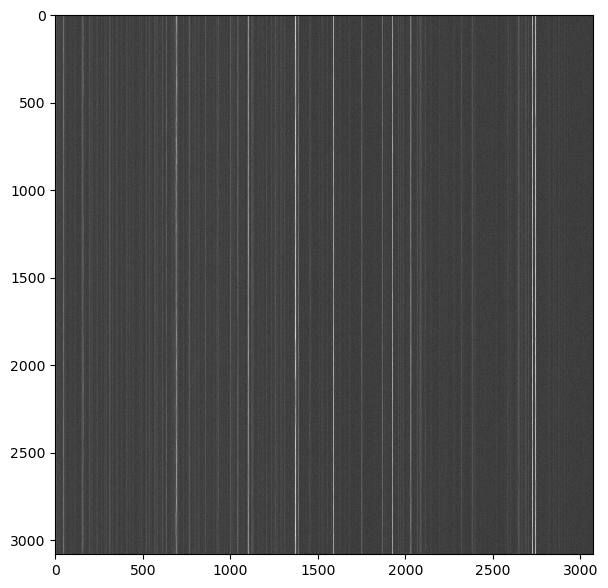

In [6]:
plt.imshow(np.sqrt(norm))

In [254]:
#right and then we need to find the streaks...

In [39]:


'''
o	For the center of the transient, choose to have at least half the transient in the image 
(randint between -5 and 26 will be the center of the gaussian for size 10 events)
o	intensities of (multiplicative factors) 7, 8, 9, 1.5, 1.3, 1.1, 1.05, 1.01
'''
np.random.seed(21) #so that i can keep the same random - last time it was seed 20

#for the center of the transient - want at least half of the transient in the image
center_values = np.random.randint(10, high = 3070, size = 58500, dtype=int) 
#adjusted this to be the whole image

#for the intensities - 7, 8, 9, 1.5, 1.3, 1.1, 1.05, 1.01, and a distribution with more at the lower intensities
#i'm feeling like - 30% 2's, 30% 3's, 20% 4's, 10% 6's, 10% 10s...idk i can make it nicer later
total_desired = 58500 #imma do math on it
intensities_8 = np.full(int(total_desired*.09), 8)
intensities_7 = np.full(int(total_desired*.09), 1.5)
intensities_105 = np.full(int(total_desired*.09), 1.3)
intensities_101 = np.full(int(total_desired*.09), 1.1)
intensities_102 = np.full(int(total_desired*.09), 1.05)
intensities_103 = np.full(int(total_desired*.09), 1.01)
intensities_2 = np.full(int(total_desired*.09), 2)
intensities_3 = np.full(int(total_desired*.09), 3)
intensities_4 = np.full(int(total_desired*.09), 4)
intensities_6 = np.full(int(total_desired*.09), 6)
intensities_10 = np.full(int(total_desired*.09), 10)

intensities = np.concatenate((intensities_2, intensities_3, intensities_4, 
                              intensities_6, intensities_10, intensities_101, 
                              intensities_102, intensities_103,
                             intensities_7, intensities_8, intensities_105 ))
np.random.shuffle(intensities) #this shuffles the array in place

#for sigma, we are not doing an array, just doing one value at a time
#previously we had sigmalist=[3,5,10,20,40,80,150,300,500,1000] #pixels
#don't spend a lot of resources on the 1000 side bc they will be hard to detect
#roughly, more objects at 3,5,10, less at higher


In [43]:
def get_image_background(image):
    '''
    this function gets the background value of an array of various brightnesses
    and iteratively clips the maximum at a 3 standard deviation level to get the background value
    input: array of any dimensions
    return: background value (float)
    '''
    
    change = 100
    newnorm = image
    while np.abs(change) > .0001:
        stdv = np.std(newnorm)
        norm_mean = np.mean(newnorm) 
        newnorm = np.clip(newnorm, 0, norm_mean+3*stdv) #check - is this the right cutoff
        newnorm_mean = np.mean(newnorm)
        change = newnorm_mean-norm_mean
        background = newnorm_mean
    return background

In [41]:
#so let's try implanting in one

def implant_transient_full_image(image, streak_x_val, center_value_y, intensity, sigma):
    '''
    this function takes an image and implants a gaussian brightening event in the given columns (in a streak).
    inputs -
    image: an array of brightness values
    streak_x_val: location of the streak - x coordinate
    center_value_y: the y value to center the gaussian at
    sigma: the sigma of the gaussian
    intensity: the maximum brightening of the gaussian
    returns:  gaussianed_image, normalized array with brightening in the streak
    '''
    
    #getting background
    background = get_image_background(image)

    #subtracting background
    imagenobackground = image - np.full(np.shape(image),background)

    #choosing which columns are part of the streak (to implant transient in)
    #careful: there could be two streaks in the image, i want the one that is the most centered
    #for now we're just taking the columns around the streak
    mid = streak_x_val #the middle column - truncated. so the lower one if even number of columns
    
    averages = np.average(imagenobackground, axis=0)
    #there should be some criteria for the gradient perhaps
    #failing that, just that it's bigger than .05 
    column_indices = []
    indices_to_check = []
    if mid < 3072-4:
        indices_to_check = [mid-4, mid-3, mid-2, mid-1, mid, mid+1, mid+2, mid+3] 
    for index in indices_to_check:
        if averages[index]>.01:
            column_indices.append(index)
    
    # print(column_indices)
    
    
    
     #now gaussianning all relevant columns
    
    gaussianed_image = imagenobackground.copy() #stamp array to modify with the gaussian brightening
    
    for i in column_indices:
        gaussianed = gaussian_event(ys = np.linspace(0,image.shape[0]-1,image.shape[0]), 
                                  M = center_value_y, sig = sigma, A = intensity, original_values = imagenobackground[:,i])
        gaussianed_image[:,i] = gaussianed
        
    #adding back background
    gaussianed_image=gaussianed_image + np.full(np.shape(image),background)
    
    #should renormalize it
    norm_gi = (gaussianed_image-np.min(gaussianed_image))/(np.max(gaussianed_image)-np.min(gaussianed_image))
    
    return norm_gi

In [45]:
def gaussian_event(ys, M, sig, A, original_values): 
    """ys should be the array of y values
    #m is the center y value
    #sig is the standard deviation
    #original_values is the original brightness (for each y value)
    #A is the maximum brightening. A-1 is in the code bc of that additional 1 later
    #return original_values * ((A-1) * (np.exp(-np.power(ys - M, 2.) / (2 * np.power(sig, 2.)))) + 1)
    """
    return original_values * ((A-1) * (np.exp(-np.power(ys - M, 2.) / (2 * np.power(sig, 2.)))) + 1)
    

In [279]:
image = norm
background = get_image_background(image)

    #subtracting background
imagenobackground = image - np.full(np.shape(image),background)

In [280]:
#okay i want a new way to make short list
averages = np.average(imagenobackground, axis=0)

(1570.0, 1585.0)

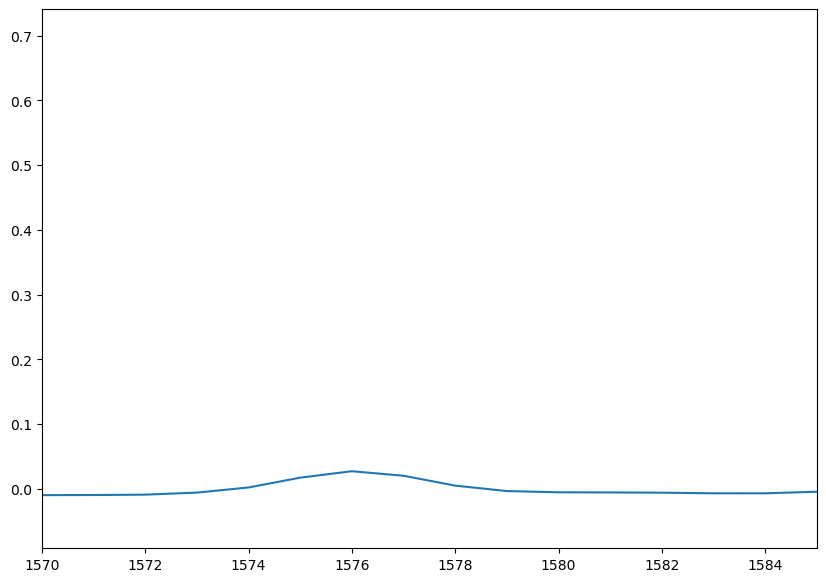

In [281]:
plt.plot(averages)
plt.xlim(1570,1585)

(1710.0, 1720.0)

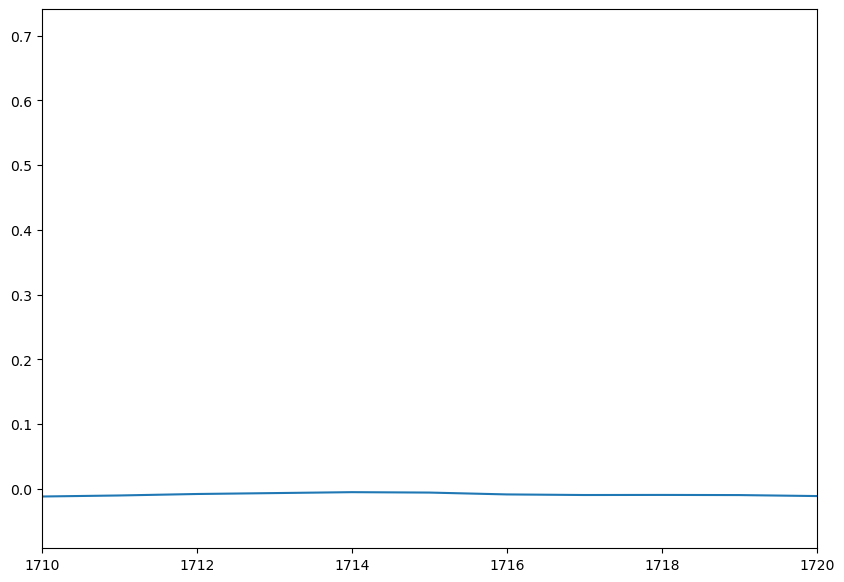

In [282]:
plt.plot(averages)
plt.xlim(1710,1720)

In [283]:
np.max(averages)

0.7030632

In [284]:
sorted = np.argsort(averages)[-20:]

In [285]:
sorted

array([1104, 2746, 2725, 1105,  931, 1589, 1927, 2727, 1590,  930, 2745,
       2726, 2743, 1373, 1375,  692, 2744,  690, 1374,  691])

In [286]:
doublesorted = np.sort(sorted)
doublesorted

array([ 690,  691,  692,  930,  931, 1104, 1105, 1373, 1374, 1375, 1589,
       1590, 1927, 2725, 2726, 2727, 2743, 2744, 2745, 2746])

In [287]:
np.hstack((doublesorted,[0]))

array([ 690,  691,  692,  930,  931, 1104, 1105, 1373, 1374, 1375, 1589,
       1590, 1927, 2725, 2726, 2727, 2743, 2744, 2745, 2746,    0])

In [288]:
shortlist = []
for i, el in enumerate(doublesorted):
    ihatenumbers = np.hstack((doublesorted,[0]))
    if ihatenumbers[i+1]!=el+1:
        shortlist.append(el)

In [289]:
shortlist

[692, 931, 1105, 1375, 1590, 1927, 2727, 2746]

In [290]:
image = norm

In [291]:
streak_x_val = shortlist[0]
center_value_y = 1000
intensity = 4
sigma = 3
implanted = implant_transient_full_image(image, streak_x_val, center_value_y, intensity, sigma)

In [5]:
def show_streak(image, streak_x_val, center_value_y=None):
    plt.imshow(np.sqrt(image), aspect=.05)
    plt.xlim(streak_x_val-10, streak_x_val+10)
    #plt.ylim(center_value_y-20, center_value_y+20)
    plt.colorbar()
    plt.show()
    if center_value_y !=None:
        plt.imshow(np.sqrt(image))
        plt.xlim(streak_x_val-20, streak_x_val+20)
        plt.ylim(center_value_y-20, center_value_y+20)
        plt.colorbar()
        plt.show()

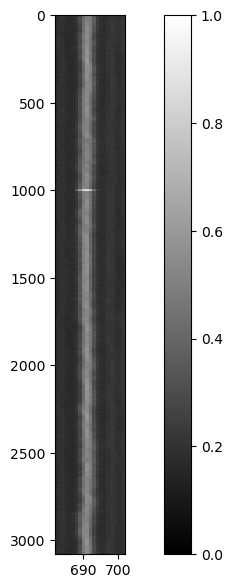

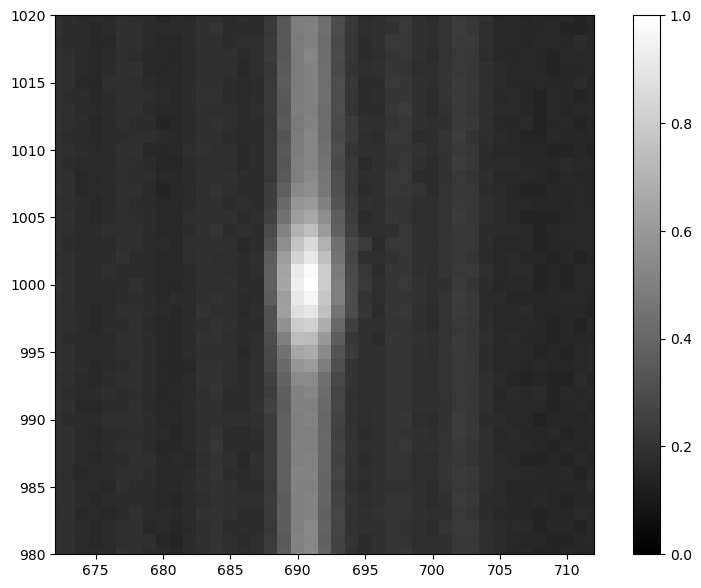

In [293]:
show_streak(implanted, streak_x_val, center_value_y)

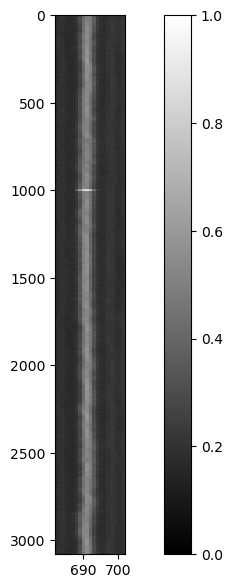

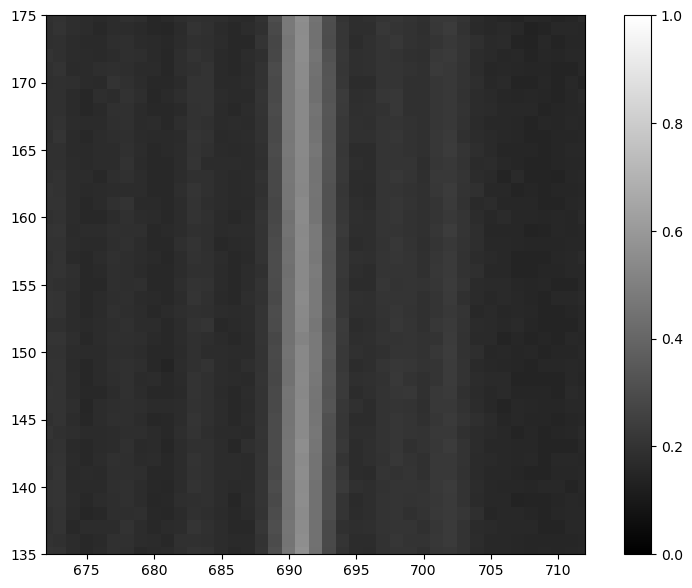

In [294]:
show_streak(implanted, streak_x_val, center_value_y=155)

In [331]:
def implant_10_transients(image, sigma, intensities, center_values, counter, plot=False):
    '''
    
    
    '''
    intensity_counter = counter
    y_counter = counter
    transient_info=[] #empty list for adding info for implanted transients
    
    #short list of where brightest streaks are
    averages = np.average(image, axis=0)
    sorted = np.argsort(averages)[-20:]
    doublesorted = np.sort(sorted)
    shortlist = []
    for i, el in enumerate(doublesorted):
        ihatenumbers = np.hstack((doublesorted,[0]))
        if ihatenumbers[i+1]!=el+1:
            shortlist.append(el)
    
    implanted = image
    for streak_x_val in shortlist[:10]: 
        center_value_y = center_values[y_counter]
        intensity = intensities[intensity_counter]
        y_counter += 1
        intensity_counter += 1  
        implanted = implant_transient_full_image(implanted, streak_x_val, center_value_y, intensity, sigma)
        # print("intensity "+str(intensity))
        # print("xval "+str(streak_x_val))
        if plot==True:
            show_streak(implanted, streak_x_val, center_value_y)
        trans_xcoord_ycoord_intensity_sigma = (streak_x_val, center_value_y,
                                                    intensity, sigma)
        print("trans xcoord etc: ", trans_xcoord_ycoord_intensity_sigma)
        transient_info.append(trans_xcoord_ycoord_intensity_sigma)
    return implanted, transient_info


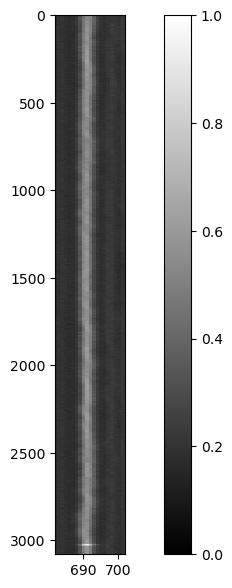

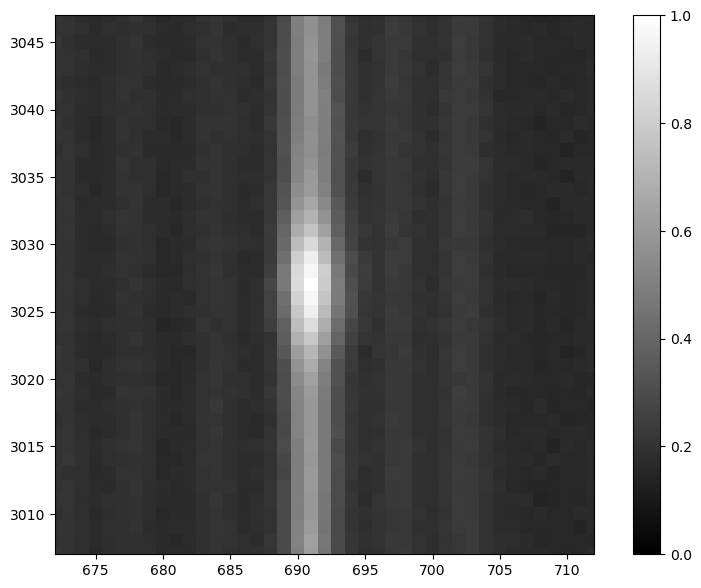

trans xcoord etc:  (692, 3027, 3.0, 3)


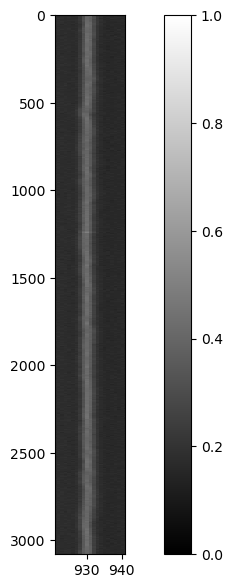

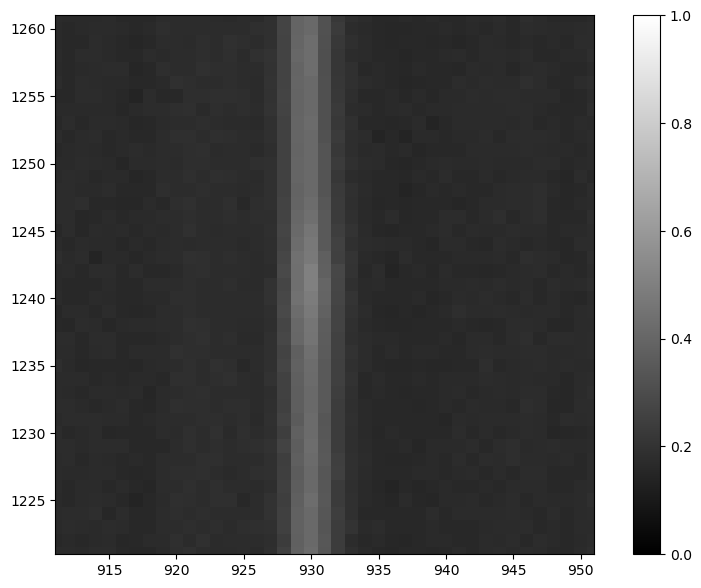

trans xcoord etc:  (931, 1241, 1.5, 3)


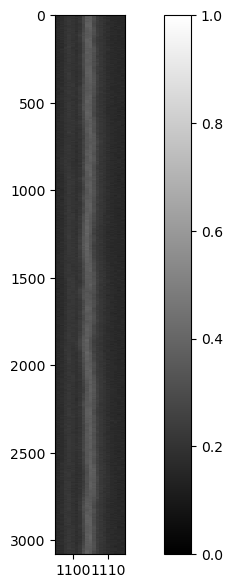

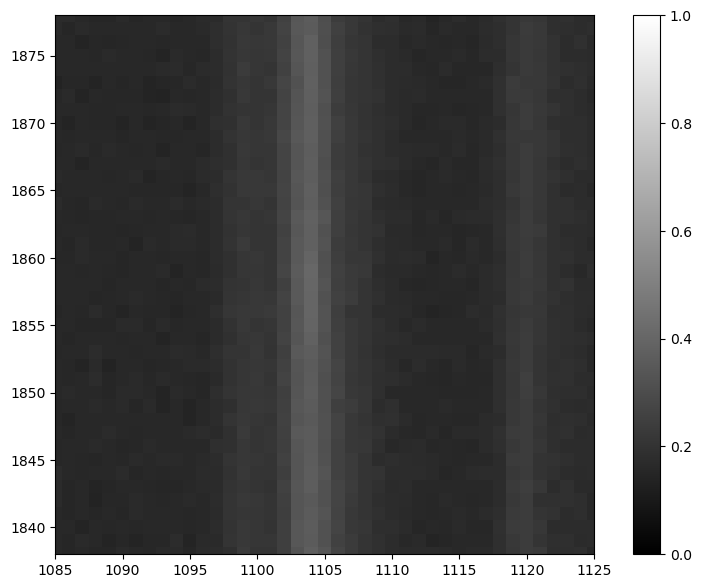

trans xcoord etc:  (1105, 1858, 1.1, 3)


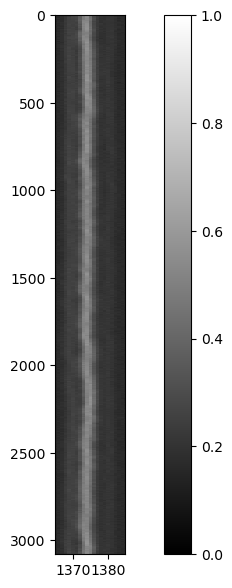

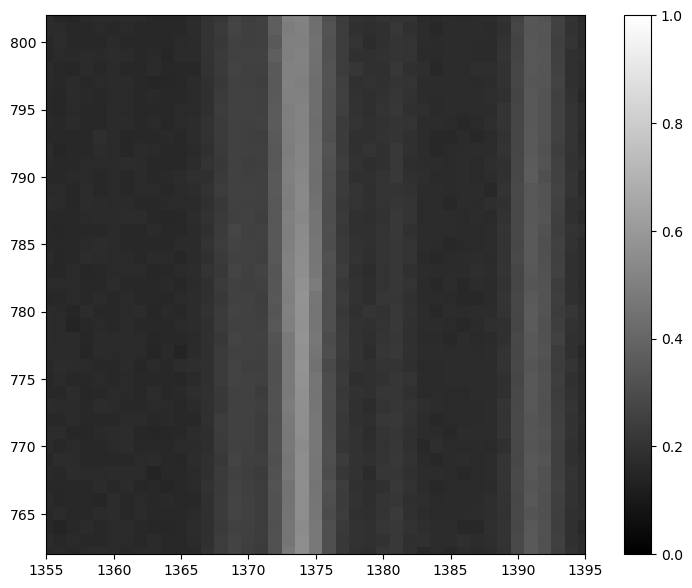

trans xcoord etc:  (1375, 782, 1.1, 3)


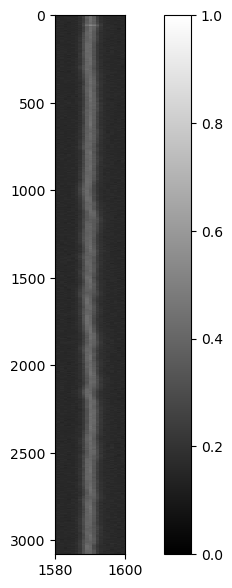

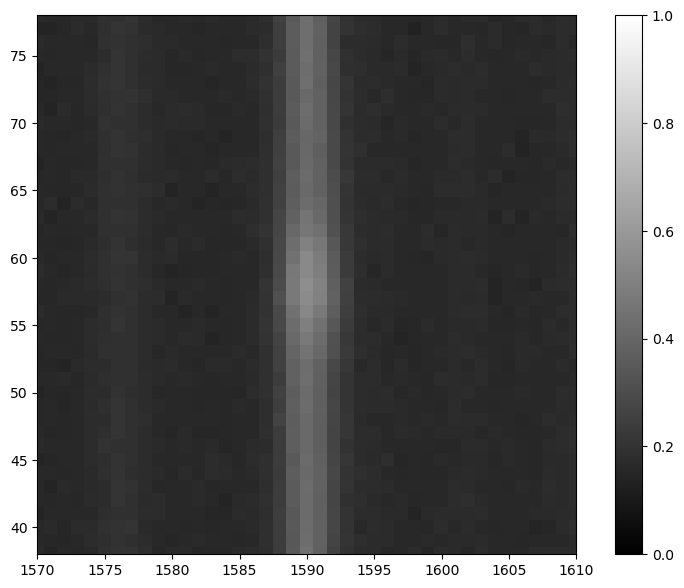

trans xcoord etc:  (1590, 58, 2.0, 3)


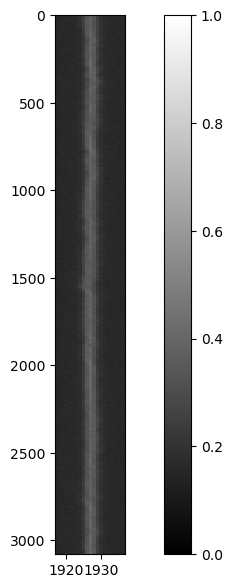

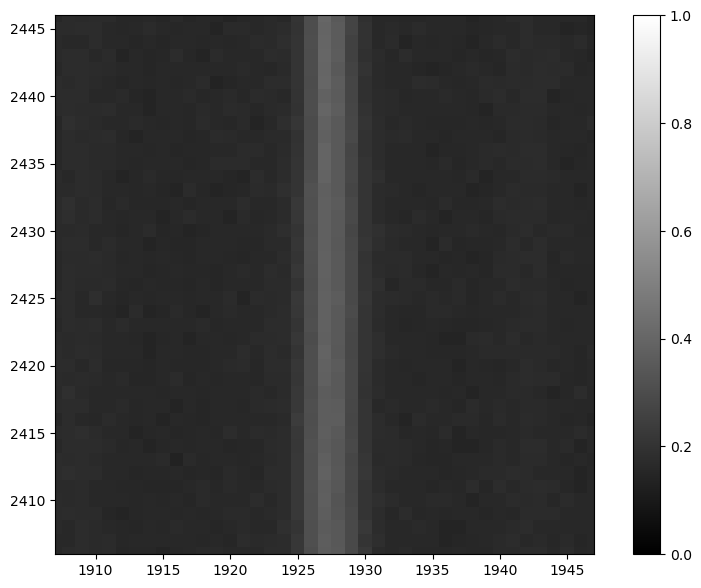

trans xcoord etc:  (1927, 2426, 1.05, 3)


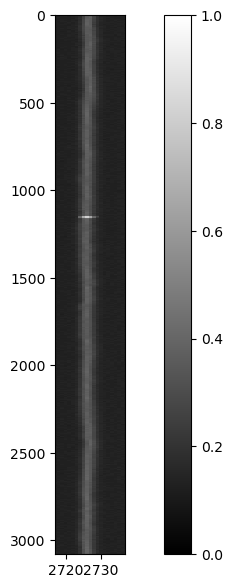

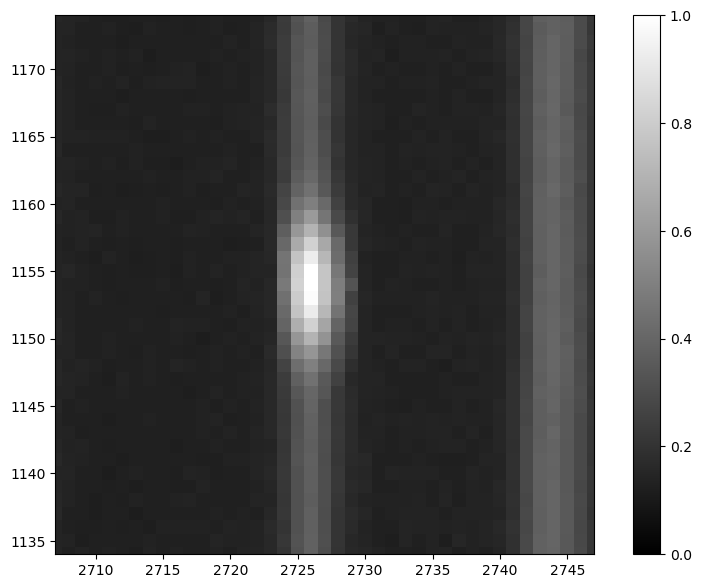

trans xcoord etc:  (2727, 1154, 8.0, 3)


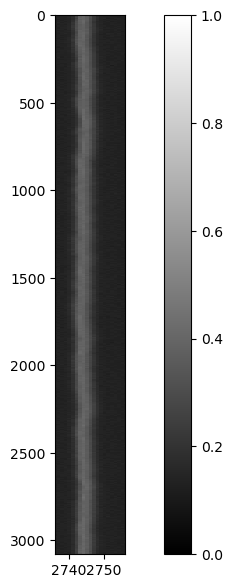

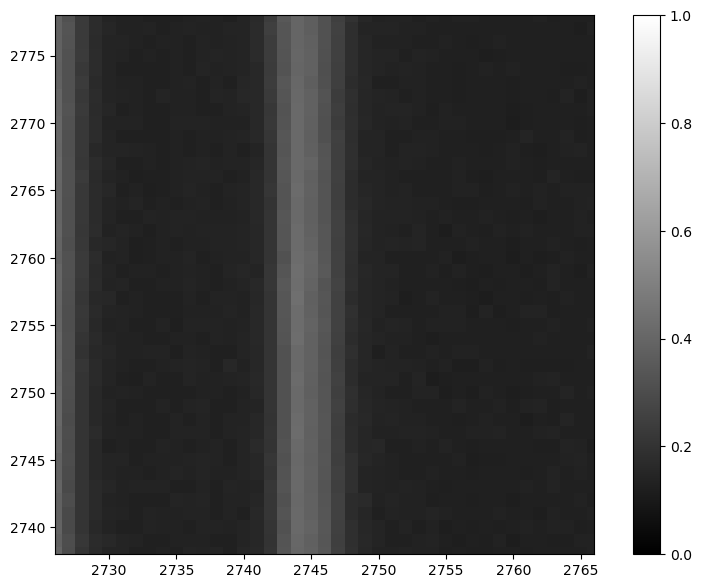

trans xcoord etc:  (2746, 2758, 1.1, 3)


(array([[0.00583436, 0.01823774, 0.02198738, ..., 0.02043181, 0.01853595,
         0.01605107],
        [0.0037401 , 0.01973786, 0.01939012, ..., 0.01583455, 0.0173144 ,
         0.01538093],
        [0.00337707, 0.01913313, 0.020982  , ..., 0.01556332, 0.01579023,
         0.01818615],
        ...,
        [0.00285247, 0.01792755, 0.02090785, ..., 0.01794685, 0.01640419,
         0.01665379],
        [0.00204823, 0.01799947, 0.02008819, ..., 0.01596771, 0.0179913 ,
         0.01692855],
        [0.00040427, 0.01627567, 0.01943866, ..., 0.01368544, 0.01806403,
         0.01545962]], dtype=float32),
 [(692, 3027, 3.0, 3),
  (931, 1241, 1.5, 3),
  (1105, 1858, 1.1, 3),
  (1375, 782, 1.1, 3),
  (1590, 58, 2.0, 3),
  (1927, 2426, 1.05, 3),
  (2727, 1154, 8.0, 3),
  (2746, 2758, 1.1, 3)])

In [296]:
implant_10_transients(image, sigma, intensities, center_values, plot=True)

In [298]:
sigma = 3
intensity_counter = 0
y_counter = 0

#short list of where brightest streaks are
averages = np.average(image, axis=0)
sorted = np.argsort(averages)[-20:]
doublesorted = np.sort(sorted)
shortlist = []
for i, el in enumerate(doublesorted):
    ihatenumbers = np.hstack((doublesorted,[0]))
    if ihatenumbers[i+1]!=el+1:
        shortlist.append(el)

implanted = image
for streak_x_val in shortlist[:10]: 
    center_value_y = center_values[y_counter]
    intensity = intensities[intensity_counter]
    y_counter += 1
    intensity_counter += 1  
    implanted = implant_transient_full_image(implanted, streak_x_val, center_value_y, intensity, sigma)
    print("intensity "+str(intensity))
    print("xval "+str(streak_x_val))
    #implant_counter += 1
    #show_streak(implanted, streak_x_val, center_value_y)

    #save the implanted info somehow

intensity 3.0
xval 692
intensity 1.5
xval 931
intensity 1.1
xval 1105
intensity 1.1
xval 1375
intensity 2.0
xval 1590
intensity 1.05
xval 1927
intensity 8.0
xval 2727
intensity 1.1
xval 2746


In [302]:
image_directory

b'/lustre/lrspec/ZTF_data/2022_1014_copy/implant_full/'

In [336]:
#HERES WHERE THE STUFF HAPPENS
path_to_save = "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/"
fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/to_implant_full/"
counter = 0

for i, file in enumerate(os.listdir(image_directory)):
    image_filename = os.fsdecode(file)
    filename_start = image_filename[:40]
    image_filename_full = fpath_image+image_filename
    #print(image_filename_full)
    hdul=fits.open(image_filename_full)
    file1_array = hdul[1].data
    norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
    image = norm
    nrow, ncol = image.shape
    imagepath = path_to_save+"images/"+str(filename_start)+"_implanted10"
    infopath = path_to_save+"info/"+str(filename_start)+"_implanted10_info"
    implanted, transient_info = implant_10_transients(image, 
                                                      sigma, intensities, 
                                                      center_values, counter=counter,
                                                      plot=False)
    np.save(imagepath, implanted)
    np.save(infopath, transient_info)
    counter+=(len(transient_info)+1)
    

trans xcoord etc:  (591, 3027, 10.0, 3)
trans xcoord etc:  (1255, 1241, 3.0, 3)
trans xcoord etc:  (1849, 1858, 1.1, 3)
trans xcoord etc:  (1857, 782, 1.05, 3)
trans xcoord etc:  (2098, 58, 8.0, 3)
trans xcoord etc:  (2363, 2426, 1.05, 3)
trans xcoord etc:  (2731, 1154, 1.05, 3)
trans xcoord etc:  (2844, 2758, 2.0, 3)
trans xcoord etc:  (182, 2569, 8.0, 3)
trans xcoord etc:  (1056, 2811, 1.5, 3)
trans xcoord etc:  (1950, 212, 1.3, 3)
trans xcoord etc:  (2055, 850, 2.0, 3)
trans xcoord etc:  (2545, 1656, 6.0, 3)
trans xcoord etc:  (145, 1799, 6.0, 3)
trans xcoord etc:  (508, 2180, 1.1, 3)
trans xcoord etc:  (560, 2362, 1.5, 3)
trans xcoord etc:  (1466, 2926, 1.5, 3)
trans xcoord etc:  (1565, 1008, 1.01, 3)
trans xcoord etc:  (2463, 2654, 3.0, 3)
trans xcoord etc:  (2617, 2718, 3.0, 3)
trans xcoord etc:  (115, 691, 10.0, 3)
trans xcoord etc:  (119, 1679, 1.3, 3)
trans xcoord etc:  (243, 496, 6.0, 3)
trans xcoord etc:  (1507, 1775, 8.0, 3)
trans xcoord etc:  (1826, 2332, 1.1, 3)
trans xco

In [ ]:
'''
TODO
fix gaussian event so that it takes only useful columns
put the functions in a .py file...
just run it on all the files...i think that's it yay

'''`

In [8]:
testfile = "ztf_20221014279051_000501_zr_c02_x_0025._implanted10.npy"
testfile_info = "ztf_20221014279051_000501_zr_c02_x_0025._implanted10_info.npy"
testfile_info_2 = "ztf_20221014279051_000501_zr_c02_x_0027._implanted10_info.npy"

In [9]:
tested = np.load("/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/"+testfile)

In [10]:
tested_info = np.load("/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/info/"+testfile_info)

In [11]:
len(tested_info)

8

In [12]:
tested_info_2 = np.load("/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/info/"+testfile_info_2)
tested_info_2

array([[1.140e+02, 2.514e+03, 8.000e+00, 3.000e+00],
       [2.650e+02, 2.367e+03, 1.000e+01, 3.000e+00],
       [4.440e+02, 2.977e+03, 6.000e+00, 3.000e+00],
       [9.490e+02, 2.257e+03, 3.000e+00, 3.000e+00],
       [1.178e+03, 2.677e+03, 1.050e+00, 3.000e+00],
       [1.320e+03, 2.023e+03, 1.050e+00, 3.000e+00],
       [1.744e+03, 2.597e+03, 4.000e+00, 3.000e+00],
       [2.819e+03, 2.359e+03, 6.000e+00, 3.000e+00]])

In [13]:
tested_info

array([[1.150e+02, 2.980e+03, 1.010e+00, 3.000e+00],
       [2.650e+02, 1.996e+03, 6.000e+00, 3.000e+00],
       [4.450e+02, 2.955e+03, 1.010e+00, 3.000e+00],
       [9.490e+02, 2.914e+03, 6.000e+00, 3.000e+00],
       [1.007e+03, 2.130e+02, 6.000e+00, 3.000e+00],
       [1.178e+03, 1.119e+03, 1.010e+00, 3.000e+00],
       [1.320e+03, 1.704e+03, 2.000e+00, 3.000e+00],
       [1.744e+03, 1.877e+03, 3.000e+00, 3.000e+00]])

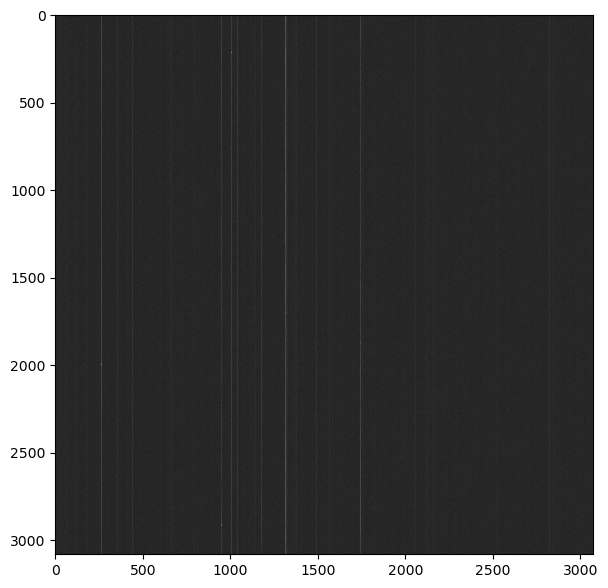

In [14]:
plt.imshow(np.sqrt(tested))

[1.15e+02 2.98e+03 1.01e+00 3.00e+00]


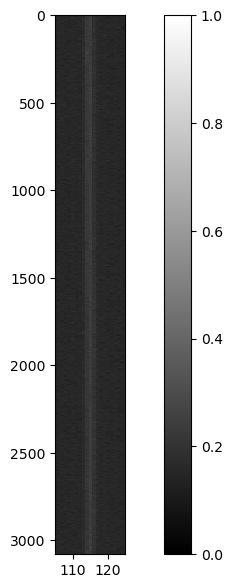

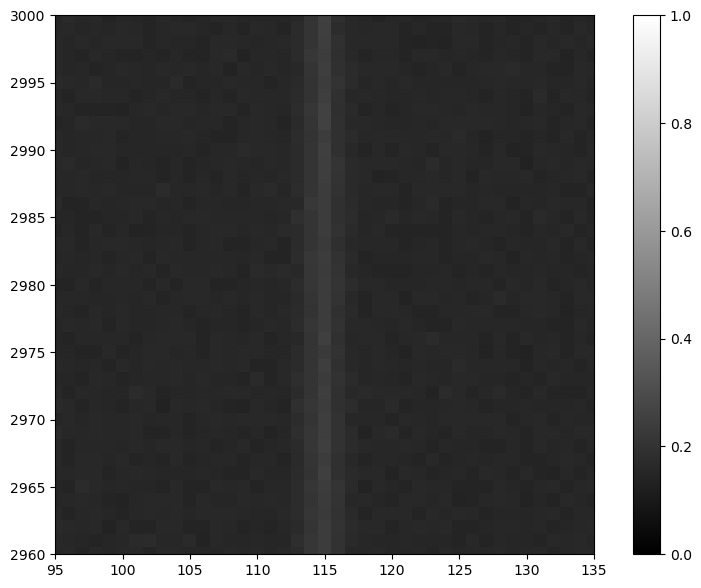

[ 265. 1996.    6.    3.]


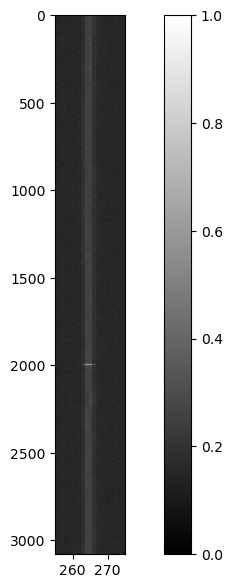

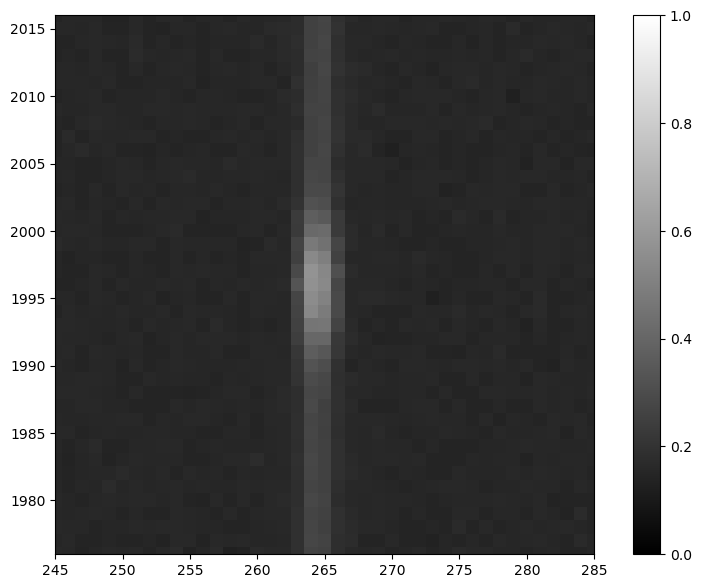

[4.450e+02 2.955e+03 1.010e+00 3.000e+00]


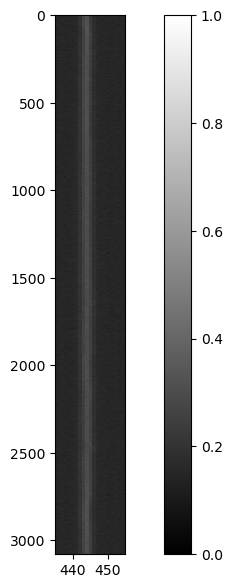

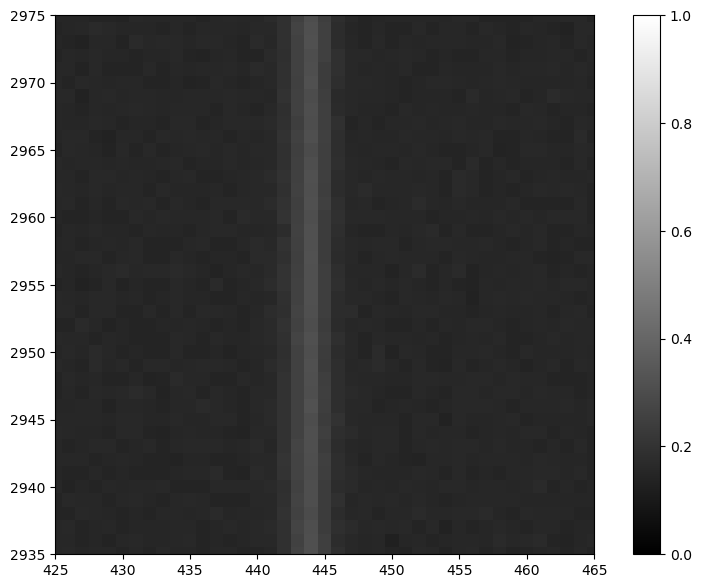

[ 949. 2914.    6.    3.]


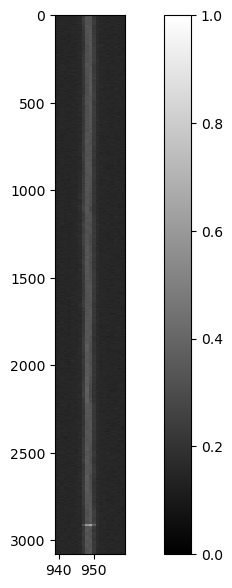

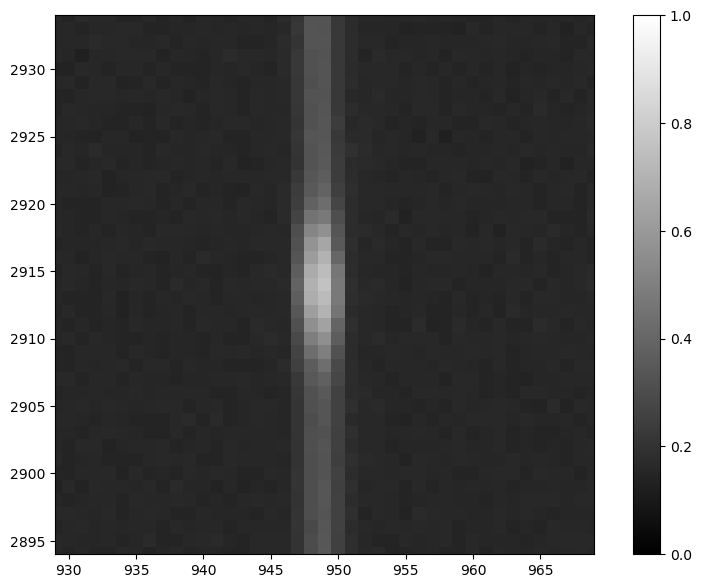

[1007.  213.    6.    3.]


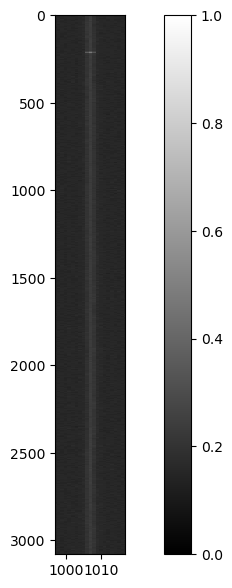

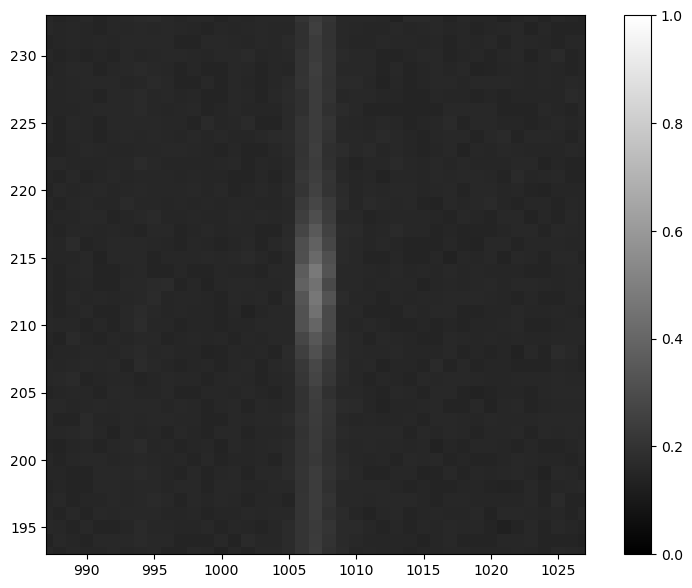

[1.178e+03 1.119e+03 1.010e+00 3.000e+00]


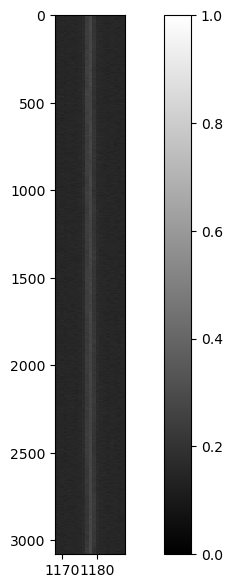

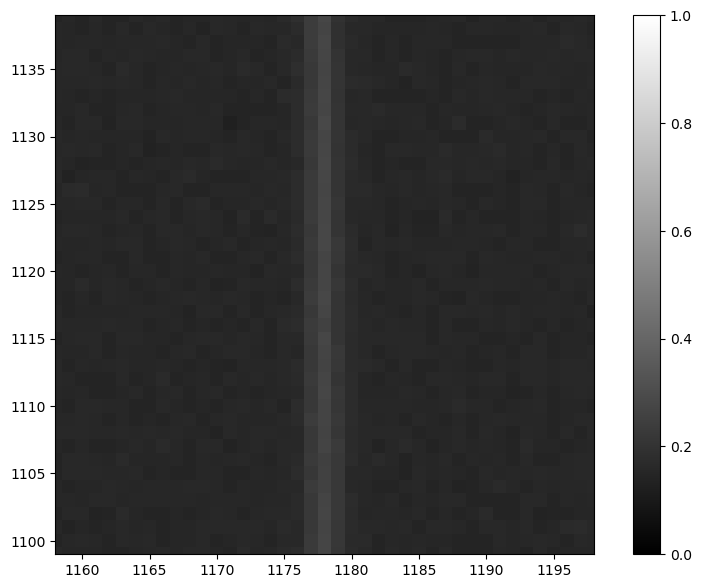

[1320. 1704.    2.    3.]


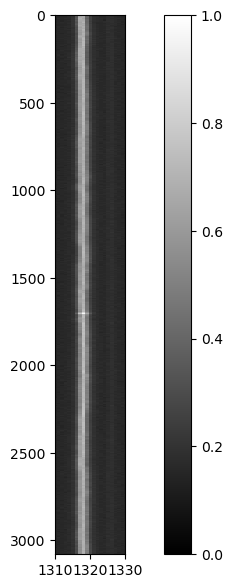

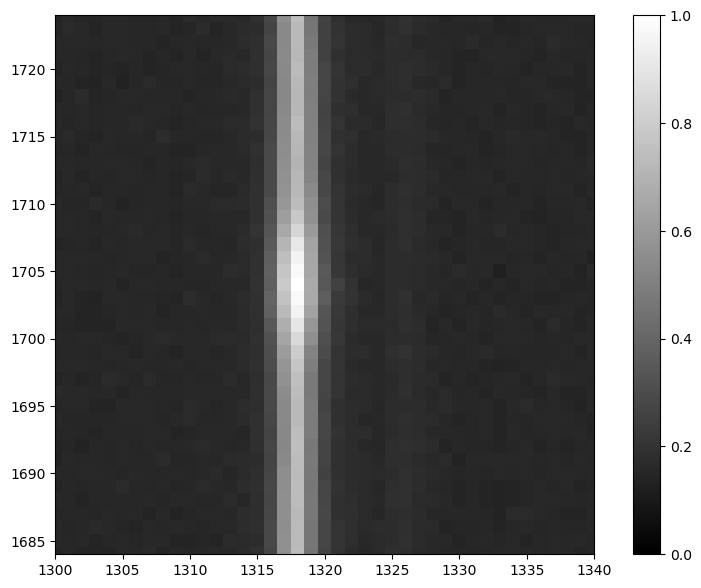

[1744. 1877.    3.    3.]


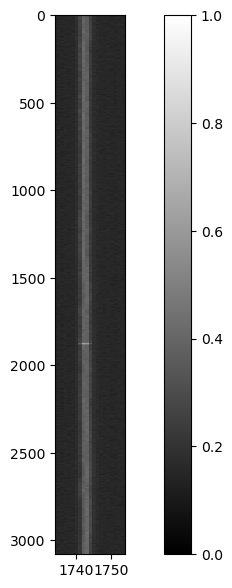

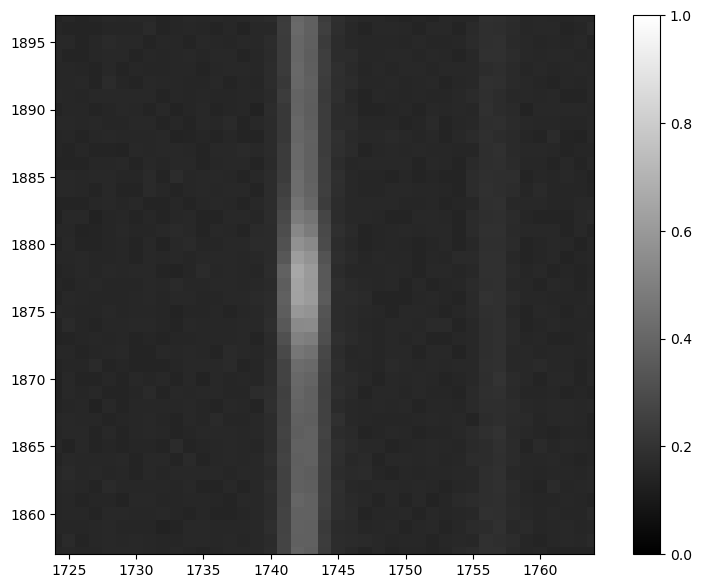

In [15]:
for arr in tested_info:
    print(arr)
    show_streak(tested, arr[0], arr[1])

In [27]:
def get_stamp(image, streak_x_val, center_value_y, plot=False):
    streak_x_val = int(streak_x_val)
    center_value_y = int(center_value_y)
    # plt.imshow(np.sqrt(image), aspect=.05)
    # plt.xlim(streak_x_val-10, streak_x_val+10)
    # #plt.ylim(center_value_y-20, center_value_y+20)
    # plt.colorbar()
    # plt.show()
    stamp = image[center_value_y-10:center_value_y+10, streak_x_val-10:streak_x_val+10]
        # plt.imshow(np.sqrt(stamp))
        # # plt.xlim(streak_x_val-20, streak_x_val+20)
        # # plt.ylim(center_value_y-20, center_value_y+20)
        # # plt.colorbar()
        # plt.show()
    if plot==True:
        plt.imshow(np.sqrt(stamp))
        plt.show()
    return stamp

array([[0.02480378, 0.02634478, 0.02224228, 0.02131866, 0.02444264,
        0.02199391, 0.02466922, 0.02645504, 0.03442601, 0.07294938,
        0.06643542, 0.03443405, 0.02563203, 0.02609996, 0.02502403,
        0.02378912, 0.02240246, 0.02356367, 0.02581903, 0.02419492],
       [0.02314907, 0.02602168, 0.02340099, 0.02306048, 0.02337801,
        0.02305291, 0.02552723, 0.02740008, 0.03367426, 0.08153754,
        0.06418942, 0.03578831, 0.0276776 , 0.02180345, 0.0206217 ,
        0.02125683, 0.02329268, 0.02471677, 0.02514908, 0.01984848],
       [0.01950439, 0.01993554, 0.0230088 , 0.02454814, 0.02498194,
        0.02006975, 0.02418261, 0.02724335, 0.03363932, 0.07797176,
        0.07301852, 0.03659485, 0.02658826, 0.02495357, 0.02215327,
        0.02224074, 0.02354433, 0.02385032, 0.02132957, 0.024683  ],
       [0.02222645, 0.02240163, 0.02193994, 0.02410481, 0.02283266,
        0.0233926 , 0.02502808, 0.02624806, 0.04093612, 0.0864549 ,
        0.07754058, 0.03487248, 0.02935973, 0

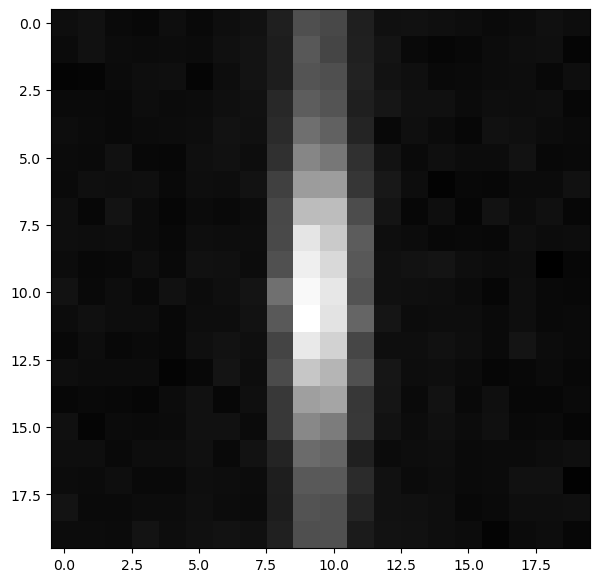

In [35]:
image = tested
streak_x_val = 265. #[ 265. 1996.    6.    3.]
center_value_y = 1996.
get_stamp(image, streak_x_val, center_value_y, plot=True)


In [83]:
def get_10_trans_stamps(image, sigma, intensities, center_values, counter, plot=False):
    '''
    mmmmmm thinking
    
    '''
    intensity_counter = counter
    y_counter = counter
    stamp_info=[] #empty list for adding info for implanted transients
    
    #short list of where brightest streaks are
    averages = np.average(image, axis=0)
    sorted = np.argsort(averages)[-20:]
    doublesorted = np.sort(sorted)
    shortlist = []
    for i, el in enumerate(doublesorted):
        ihatenumbers = np.hstack((doublesorted,[0]))
        if ihatenumbers[i+1]!=el+1 and el>10 and el<(len(averages)-10):
            shortlist.append(el)
    
    implanted = image
    stamps_implanted=[]
    for streak_x_val in shortlist[:10]: 
        center_value_y = center_values[y_counter]
        intensity = intensities[intensity_counter]
        y_counter += 1
        intensity_counter += 1  
        implanted = implant_transient_full_image(implanted, streak_x_val, center_value_y, intensity, sigma)
        # print("intensity "+str(intensity))
        # print("xval "+str(streak_x_val))
        if plot==True:
            #show_streak(implanted, streak_x_val, center_value_y)
            get_stamp(implanted, streak_x_val, center_value_y, plot=True)
        intensity_sigma = (intensity, sigma)
        print("stamp info: ", intensity_sigma)
        stamp_info.append(intensity_sigma)
        stamp = get_stamp(implanted, streak_x_val, center_value_y, plot=False)
        stamps_implanted.append(stamp)
    return stamps_implanted, stamp_info



In [84]:
np.random.seed(22) #so that i can keep the same random

#for the center of the transient - want at least half of the transient in the image
center_values_new = np.random.randint(10, high = 3070, size = 58500, dtype=int) 

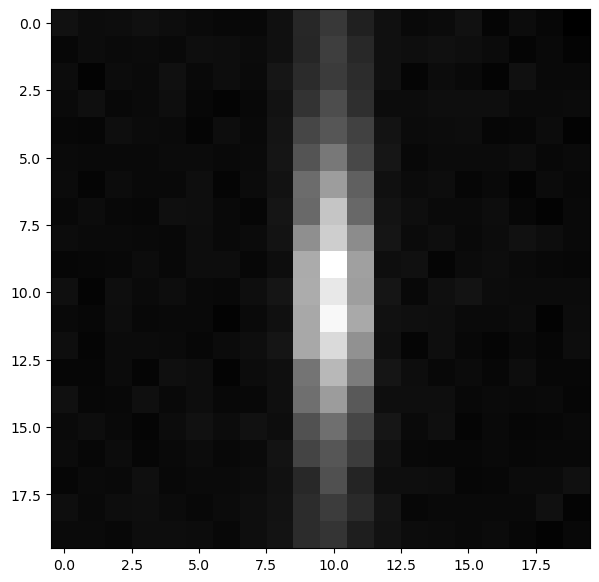

stamp info:  (10.0, 3)


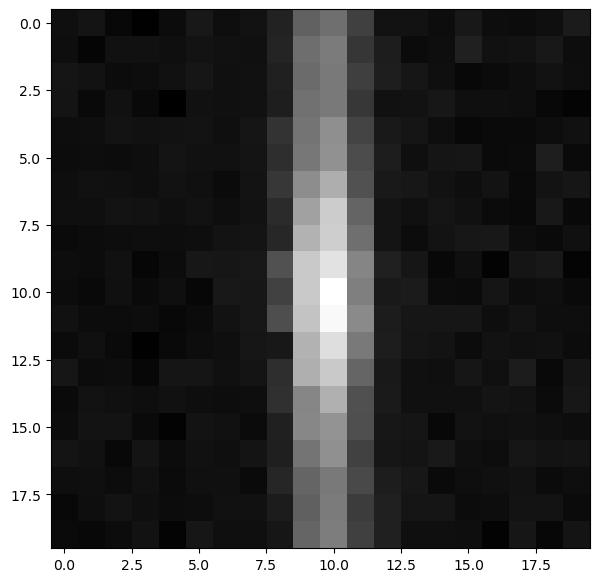

stamp info:  (3.0, 3)


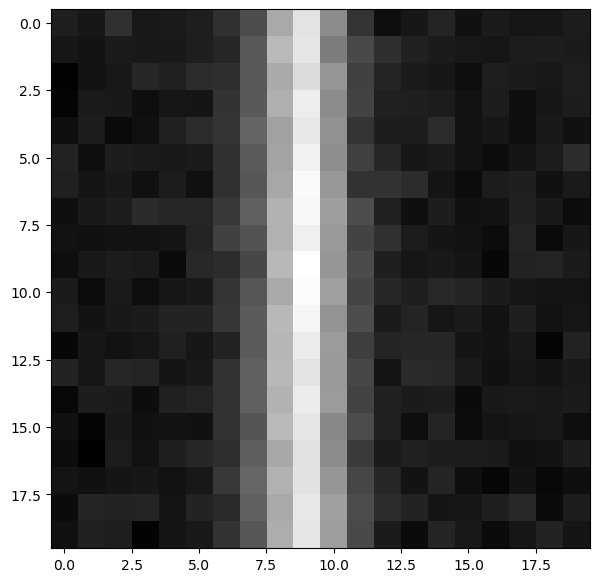

stamp info:  (1.1, 3)


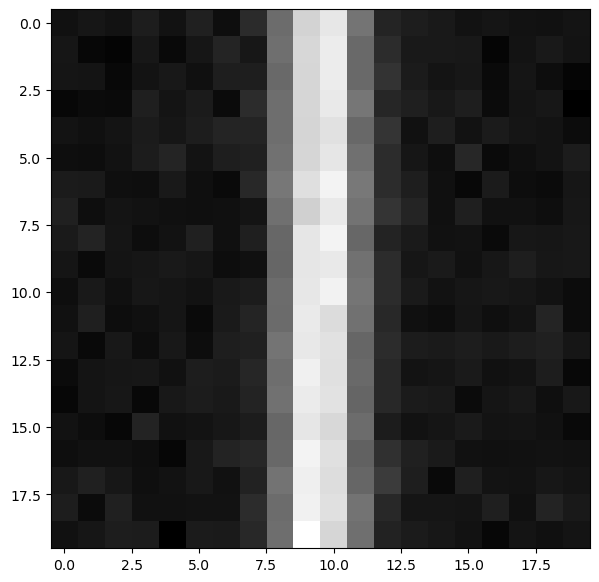

stamp info:  (1.05, 3)


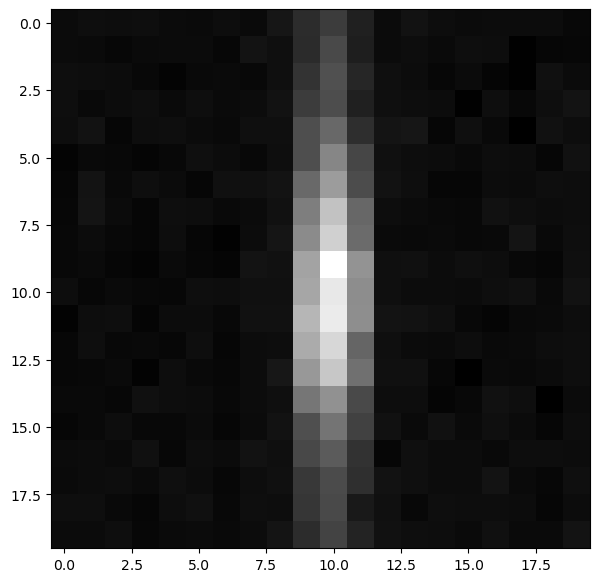

stamp info:  (8.0, 3)


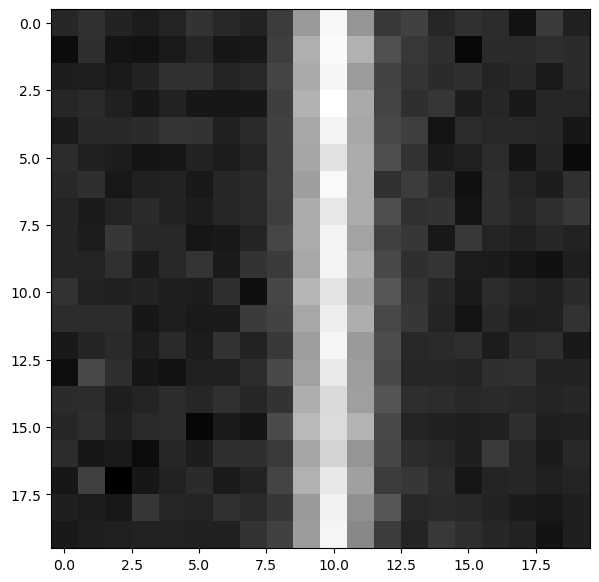

stamp info:  (1.05, 3)


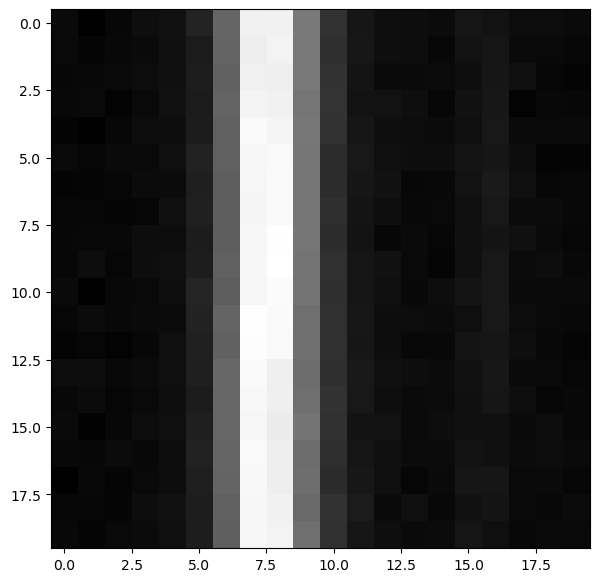

stamp info:  (1.05, 3)


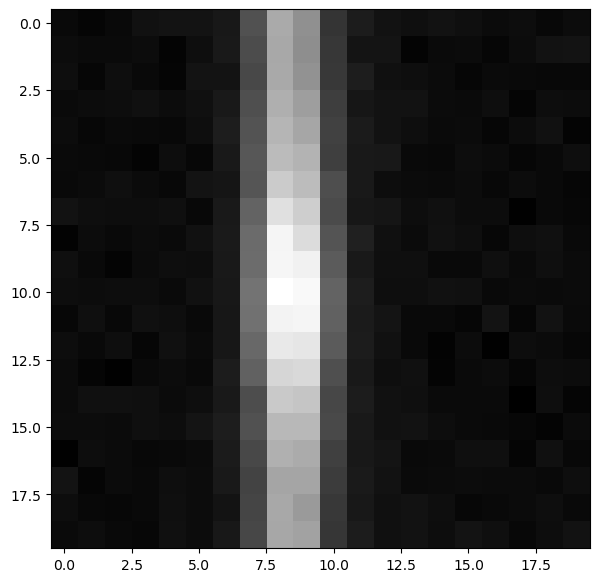

stamp info:  (2.0, 3)


In [69]:
image = tested
sigma = 3
intensities = intensities
center_values = center_values_new
counter = 0
stamps_implanted, stamp_info  = get_10_trans_stamps(image, sigma, intensities, center_values_new, counter, plot=True)

In [74]:
stamp_info 

[(10.0, 3), (3.0, 3), (1.1, 3), (1.05, 3), (8.0, 3), (1.05, 3), (1.05, 3)]

In [86]:
#HERES WHERE THE STUFF HAPPENS for the postage stamps
path_to_save = "/lustre/lrspec/ZTF_data/2022_1014_copy/stamps_trans/"
fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/implant_train/"

for i, file in enumerate(os.listdir(fpath_image)):
    image_filename = os.fsdecode(file)
    filename_start = image_filename[:40]
    image_filename_full = fpath_image+image_filename
    print(image_filename)
    hdul=fits.open(image_filename_full)
    file1_array = hdul[1].data
    norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
    image = norm
    nrow, ncol = image.shape
    imagepath = path_to_save+"images/"+str(filename_start)+"_stamps"
    infopath = path_to_save+"info/"+str(filename_start)+"_stamps_info"
    stamps_implanted, stamp_info  = get_10_trans_stamps(image, sigma, 
                                                        intensities, 
                                                        center_values_new, counter, plot=False)
    np.save(imagepath, stamps_implanted)
    np.save(infopath, stamp_info)
    counter+=(len(stamp_info)+1)

ztf_20221014279051_000501_zr_c04_x_0008.fits.fz
stamp info:  (1.3, 3)
stamp info:  (1.05, 3)
stamp info:  (3.0, 3)
stamp info:  (8.0, 3)
stamp info:  (1.5, 3)
stamp info:  (1.5, 3)
stamp info:  (1.05, 3)
stamp info:  (4.0, 3)
stamp info:  (1.3, 3)
ztf_20221014279051_000501_zr_c15_x_0006.fits.fz
stamp info:  (1.1, 3)
stamp info:  (4.0, 3)
stamp info:  (10.0, 3)
stamp info:  (3.0, 3)
stamp info:  (10.0, 3)
stamp info:  (2.0, 3)
stamp info:  (6.0, 3)
stamp info:  (1.3, 3)
stamp info:  (1.1, 3)
stamp info:  (1.01, 3)
ztf_20221014169178_000802_zi_c12_x_0014.fits.fz
stamp info:  (1.3, 3)
stamp info:  (1.05, 3)
stamp info:  (4.0, 3)
stamp info:  (3.0, 3)
stamp info:  (4.0, 3)
stamp info:  (10.0, 3)
stamp info:  (1.01, 3)
stamp info:  (4.0, 3)
stamp info:  (4.0, 3)
ztf_20221014162894_000802_zg_c07_x_0004.fits.fz
stamp info:  (1.5, 3)
stamp info:  (1.05, 3)
stamp info:  (10.0, 3)
stamp info:  (1.3, 3)
stamp info:  (1.5, 3)
stamp info:  (1.01, 3)
ztf_20221014279051_000501_zr_c09_x_0016.fits.fz
s

ztf_20221014162894_000802_zg_c08_x_0006.fits.fz


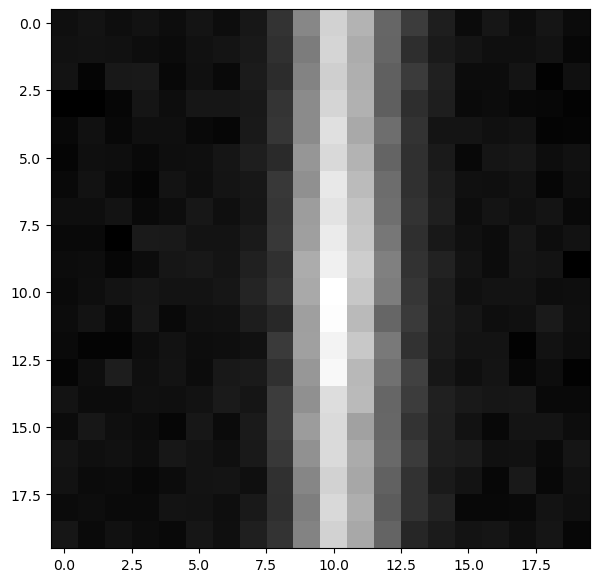

stamp info:  (1.3, 3)


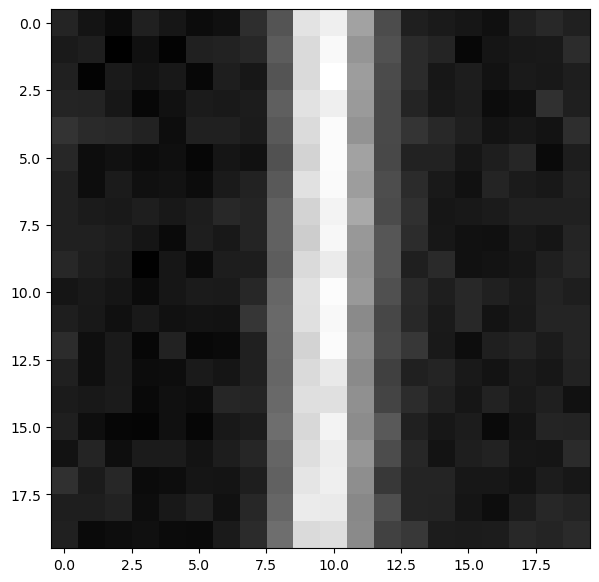

stamp info:  (1.05, 3)


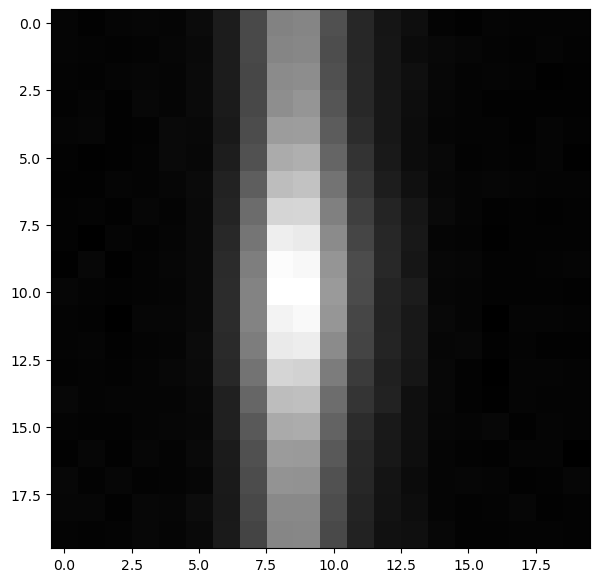

stamp info:  (3.0, 3)


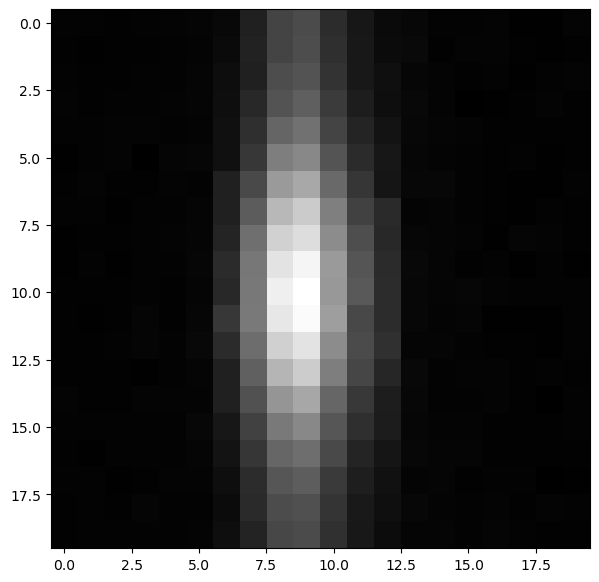

stamp info:  (8.0, 3)


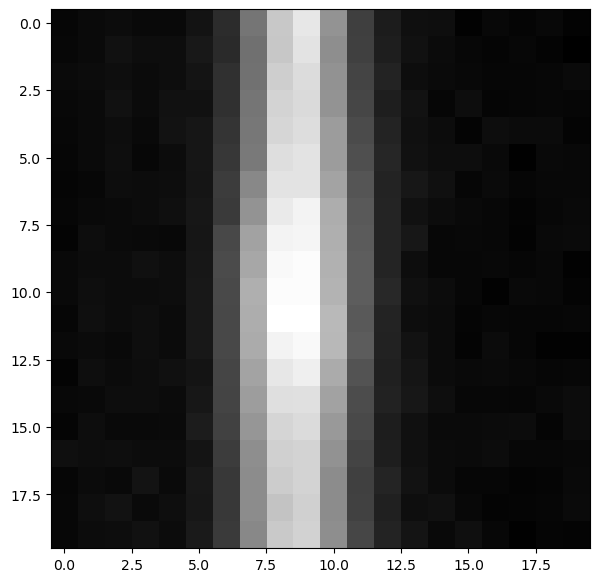

stamp info:  (1.5, 3)


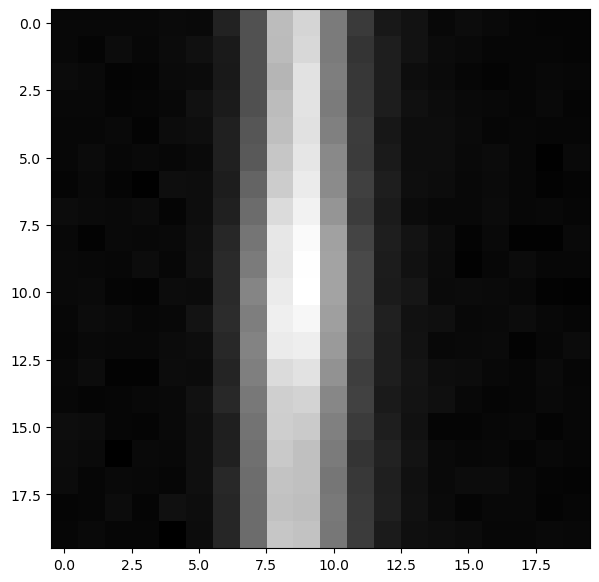

stamp info:  (1.5, 3)


In [85]:
# i=0
# image_filename = "ztf_20221014162894_000802_zg_c08_x_0006.fits.fz"
# filename_start = image_filename[:40]
# image_filename_full = fpath_image+image_filename
# print(image_filename)
# hdul=fits.open(image_filename_full)
# file1_array = hdul[1].data
# norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
# image = norm
# nrow, ncol = image.shape
# imagepath = path_to_save+"images/"+str(filename_start)+"_stamps"
# infopath = path_to_save+"info/"+str(filename_start)+"_stamps_info"
# stamps_implanted, stamp_info  = get_10_trans_stamps(image, sigma, 
#                                                     intensities, 
#                                                     center_values_new, counter, plot=True)

In [1]:
testfile = "ztf_20221014279051_000501_zr_c16_x_0006._stamps.npy"
testinfo = "ztf_20221014279051_000501_zr_c16_x_0006._stamps_info.npy"

In [93]:
tested = np.load("/lustre/lrspec/ZTF_data/2022_1014_copy/stamps_trans/images/"+testfile)
tested_info = np.load("/lustre/lrspec/ZTF_data/2022_1014_copy/stamps_trans/info/"+testinfo)

In [94]:
tested_info

array([[ 2.  ,  3.  ],
       [ 4.  ,  3.  ],
       [ 1.05,  3.  ],
       [ 1.5 ,  3.  ],
       [10.  ,  3.  ],
       [ 4.  ,  3.  ],
       [ 6.  ,  3.  ],
       [ 1.05,  3.  ],
       [ 1.3 ,  3.  ],
       [ 6.  ,  3.  ]])

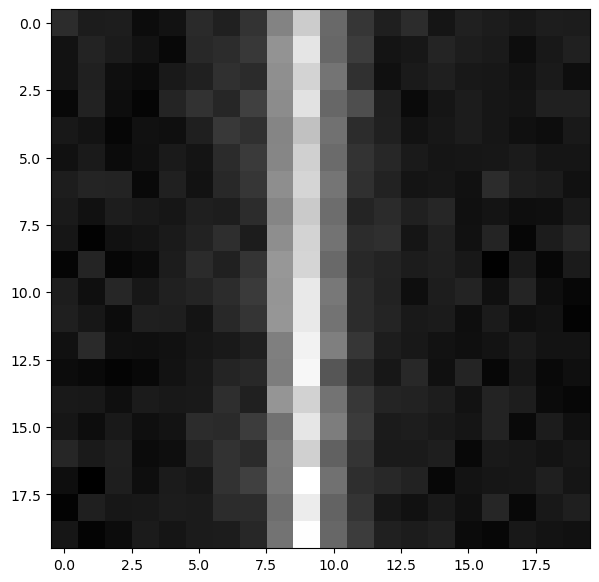

In [95]:
plt.imshow(tested[2])

In [97]:
def get_10_streak_stamps(image, center_values, counter, plot=False):
    '''
    mmmmmm thinking
    
    '''
    intensity_counter = counter
    y_counter = counter
    
    #short list of where brightest streaks are
    averages = np.average(image, axis=0)
    sorted = np.argsort(averages)[-20:]
    doublesorted = np.sort(sorted)
    shortlist = []
    for i, el in enumerate(doublesorted):
        ihatenumbers = np.hstack((doublesorted,[0]))
        if ihatenumbers[i+1]!=el+1 and el>10 and el<(len(averages)-10):
            shortlist.append(el)
    
    implanted = image
    stamps_implanted=[]
    for streak_x_val in shortlist[:10]: 
        center_value_y = center_values[y_counter]
        y_counter += 1
        intensity_counter += 1  
        # implanted = implant_transient_full_image(implanted, streak_x_val, center_value_y, intensity, sigma)
        # # print("intensity "+str(intensity))
        # # print("xval "+str(streak_x_val))
        if plot==True:
            #show_streak(implanted, streak_x_val, center_value_y)
            get_stamp(implanted, streak_x_val, center_value_y, plot=True)
        stamp = get_stamp(implanted, streak_x_val, center_value_y, plot=False)
        stamps_implanted.append(stamp)
    return stamps_implanted



In [98]:
np.random.seed(23) #so that i can keep the same random

#for the center of the transient - want at least half of the transient in the image
center_values_new_2 = np.random.randint(10, high = 3070, size = 58500, dtype=int) 

In [108]:
#HERES WHERE THE STUFF HAPPENS for the postage stamps
path_to_save = "/lustre/lrspec/ZTF_data/2022_1014_copy/stamps_no_trans/"
fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/implant_train/"

counter=0

for i, file in enumerate(os.listdir(fpath_image)):
    image_filename = os.fsdecode(file)
    filename_start = image_filename[:40]
    image_filename_full = fpath_image+image_filename
    print(image_filename)
    hdul=fits.open(image_filename_full)
    file1_array = hdul[1].data
    norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
    image = norm
    nrow, ncol = image.shape
    imagepath = path_to_save+"images/"+str(filename_start)+"_stamps"
    stamps_implanted   = get_10_streak_stamps(image,
                                            center_values_new_2, counter, plot=False)
    np.save(imagepath, stamps_implanted)
    counter+=(len(stamp_info)+1)

ztf_20221014279051_000501_zr_c04_x_0008.fits.fz
ztf_20221014279051_000501_zr_c15_x_0006.fits.fz
ztf_20221014169178_000802_zi_c12_x_0014.fits.fz
ztf_20221014162894_000802_zg_c07_x_0004.fits.fz
ztf_20221014279051_000501_zr_c09_x_0016.fits.fz
ztf_20221014169178_000802_zi_c10_x_0004.fits.fz
ztf_20221014162894_000802_zg_c05_x_0014.fits.fz
ztf_20221014279051_000501_zr_c06_x_0018.fits.fz
ztf_20221014169178_000802_zi_c14_x_0024.fits.fz
ztf_20221014279051_000501_zr_c11_x_0026.fits.fz
ztf_20221014162894_000802_zg_c03_x_0024.fits.fz
ztf_20221014279051_000501_zr_c06_x_0014.fits.fz
ztf_20221014162894_000802_zg_c14_x_0016.fits.fz
ztf_20221014169178_000802_zi_c01_x_0006.fits.fz
ztf_20221014162894_000802_zg_c05_x_0018.fits.fz
ztf_20221014169178_000802_zi_c10_x_0008.fits.fz
ztf_20221014162894_000802_zg_c07_x_0008.fits.fz
ztf_20221014169178_000802_zi_c12_x_0018.fits.fz
ztf_20221014162894_000802_zg_c08_x_0006.fits.fz
ztf_20221014279051_000501_zr_c04_x_0004.fits.fz
ztf_20221014162894_000802_zg_c16_x_0006.

In [101]:
i=0


# image_filename = os.fsdecode(file)
# filename_start = image_filename[:40]
# image_filename_full = fpath_image+image_filename
# print(image_filename)
# hdul=fits.open(image_filename_full)
# file1_array = np.load("/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/"+testfile)
# norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
image = norm
nrow, ncol = image.shape
imagepath = path_to_save+"images/"+str(filename_start)+"_stamps"
stamps_implanted   = get_10_streak_stamps(image,
                                        center_values_new_2, counter, plot=False)
#np.save(imagepath, stamps_implanted)
counter+=(len(stamp_info)+1)

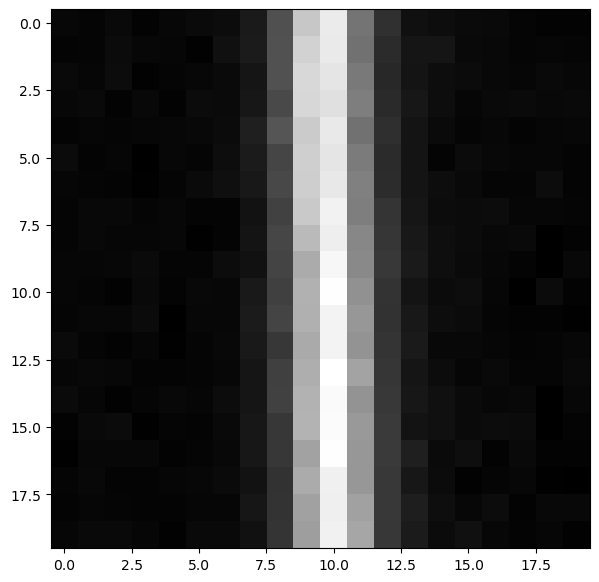

In [106]:
plt.imshow(stamps_implanted[4])

In [19]:
averages = np.average(norm, axis=0)
sorted = np.argsort(averages)[-50:]
doublesorted = np.sort(sorted)
shortlist = []
for i, el in enumerate(doublesorted):
    ihatenumbers = np.hstack((doublesorted,[0]))
    if ihatenumbers[i+1]!=el+1 and el>10 and el<(len(averages)-10):
        shortlist.append(el)

In [20]:
doublesorted

array([  47,   48,  159,  160,  161,  635,  689,  690,  691,  692,  693,
        929,  930,  931, 1103, 1104, 1105, 1106, 1372, 1373, 1374, 1375,
       1376, 1391, 1392, 1393, 1455, 1588, 1589, 1590, 1591, 1926, 1927,
       1928, 2028, 2029, 2112, 2113, 2585, 2586, 2725, 2726, 2727, 2728,
       2742, 2743, 2744, 2745, 2746, 2747])

In [21]:
shortlist

[48,
 161,
 635,
 693,
 931,
 1106,
 1376,
 1393,
 1455,
 1591,
 1928,
 2029,
 2113,
 2586,
 2728,
 2747]

In [22]:
def intermediate_values(shortlist):
    intermediate_values = []
    for i in range(len(shortlist)-1):
        if shortlist[i]+25<shortlist[i+1]:
            intermed = int((shortlist[i]+shortlist[i+1])/2)
            intermediate_values.append(intermed)
    return intermediate_values

In [23]:
intermediate_values(shortlist)

[104, 398, 664, 812, 1018, 1241, 1424, 1523, 1759, 1978, 2071, 2349, 2657]

In [25]:
np.random.seed(25) #so that i can keep the same random

#for the center of the transient - want at least half of the transient in the image
center_values_new_3 = np.random.randint(10, high = 3070, size = 58500, dtype=int) 

In [38]:
def get_10_background_stamps(image, center_values, counter, plot=False):
    '''
    mmmmmm thinking
    
    '''
    intensity_counter = counter
    y_counter = counter
    
    #short list of where brightest streaks are
    averages = np.average(image, axis=0)
    sorted = np.argsort(averages)[-70:]
    doublesorted = np.sort(sorted)
    shortlist = []
    for i, el in enumerate(doublesorted):
        ihatenumbers = np.hstack((doublesorted,[0]))
        if ihatenumbers[i+1]!=el+1 and el>10 and el<(len(averages)-10):
            shortlist.append(el)
            
    int_vals = intermediate_values(shortlist)
    
    implanted = image
    stamps_bg=[]
    for bg_x_val in int_vals: 
        center_value_y = center_values[y_counter]
        y_counter += 1
        intensity_counter += 1  
        if plot==True:
            get_stamp(implanted, bg_x_val, center_value_y, plot=True)
        stamp = get_stamp(implanted, bg_x_val, center_value_y, plot=False)
        stamps_bg.append(stamp)
    return stamps_bg



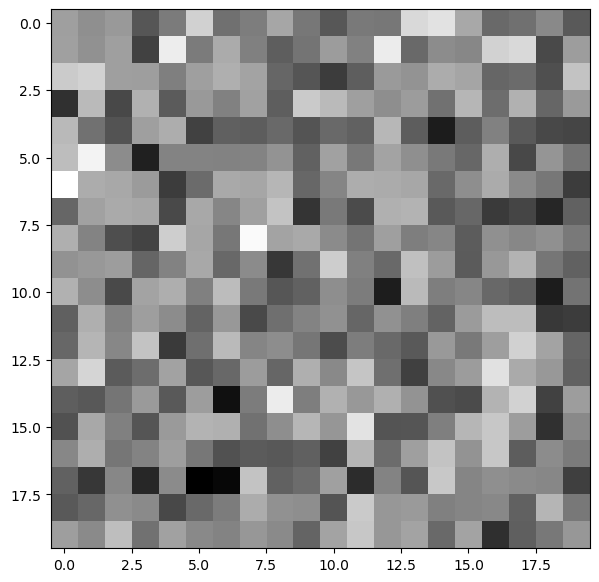

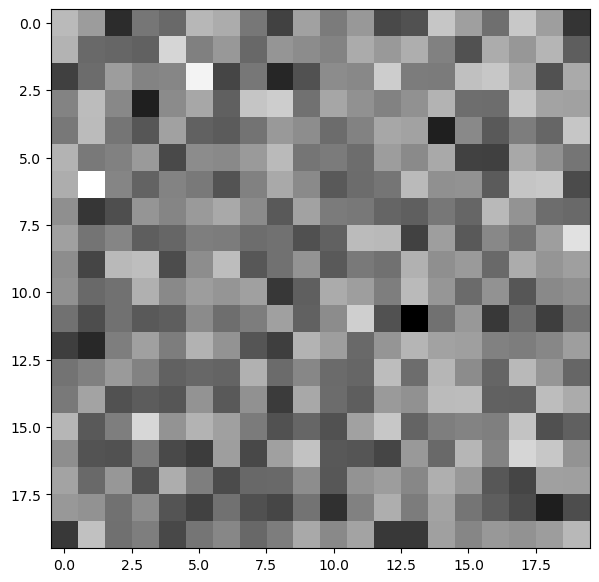

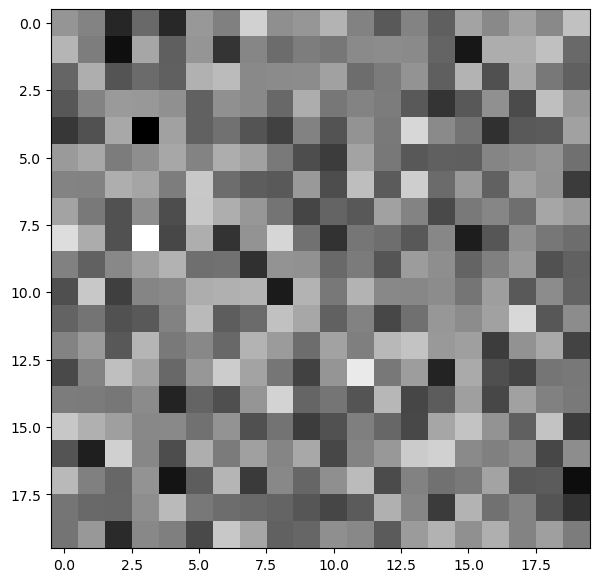

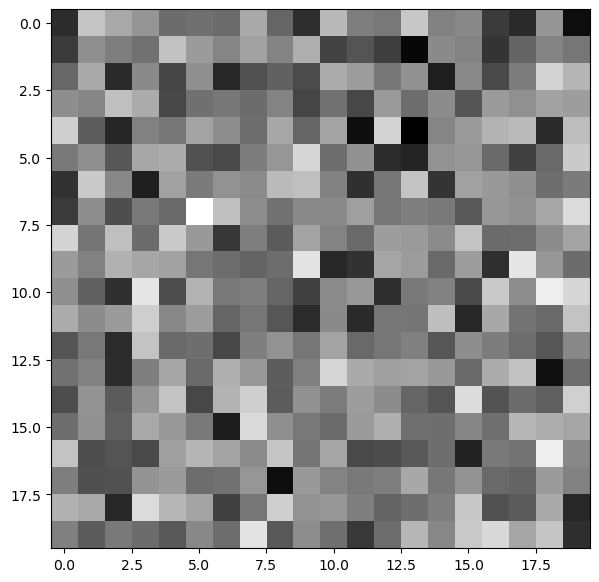

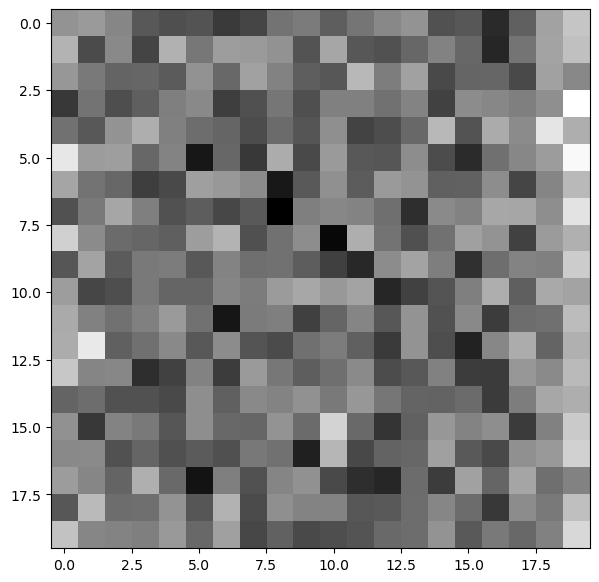

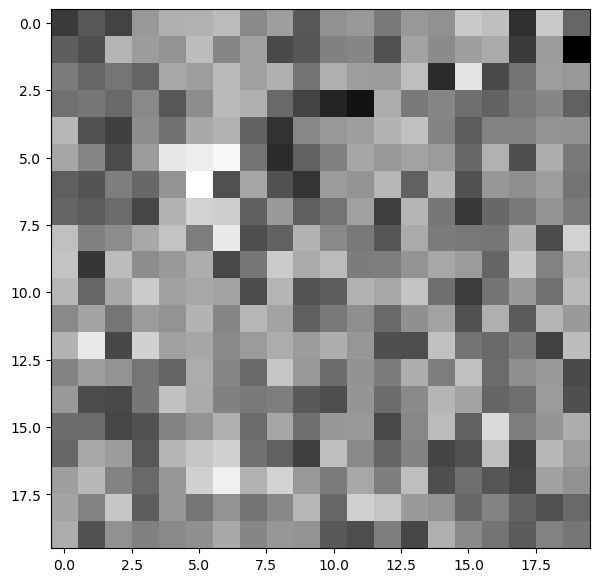

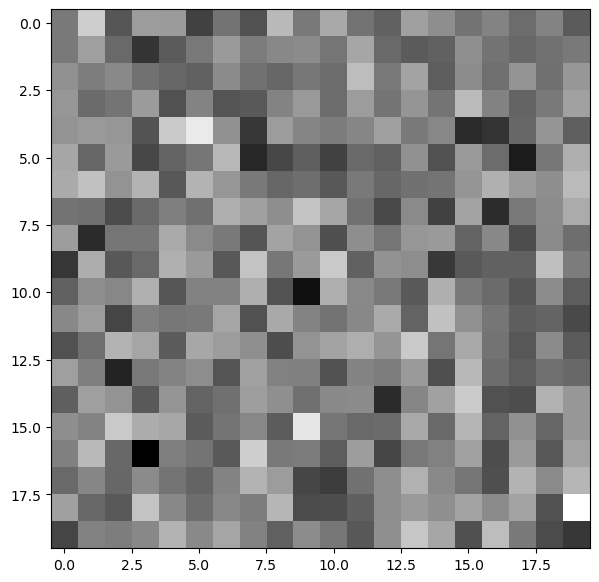

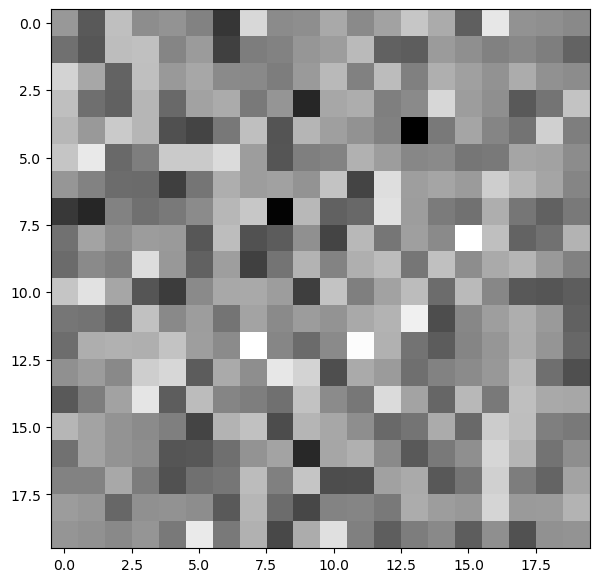

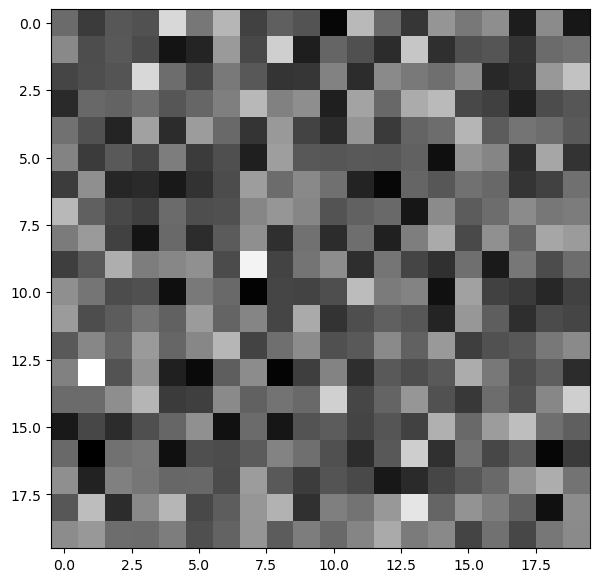

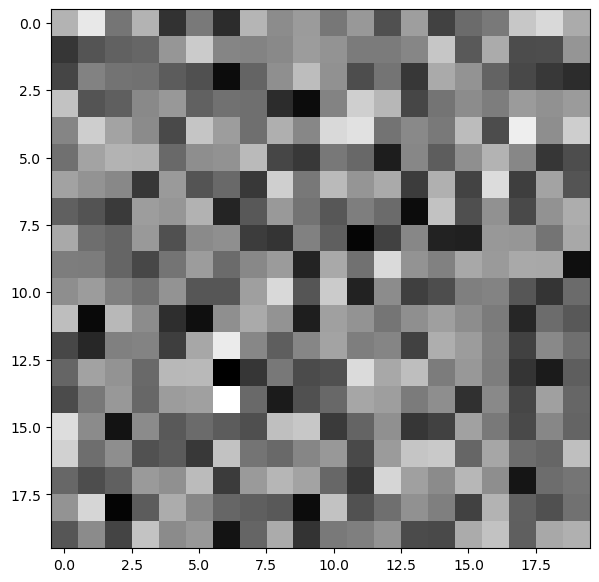

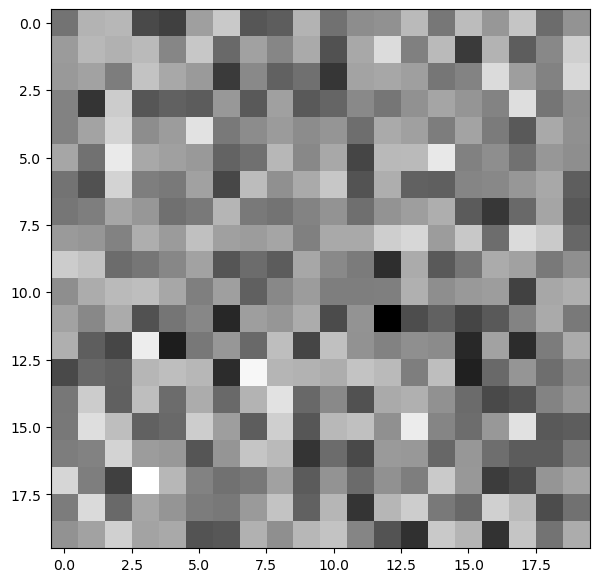

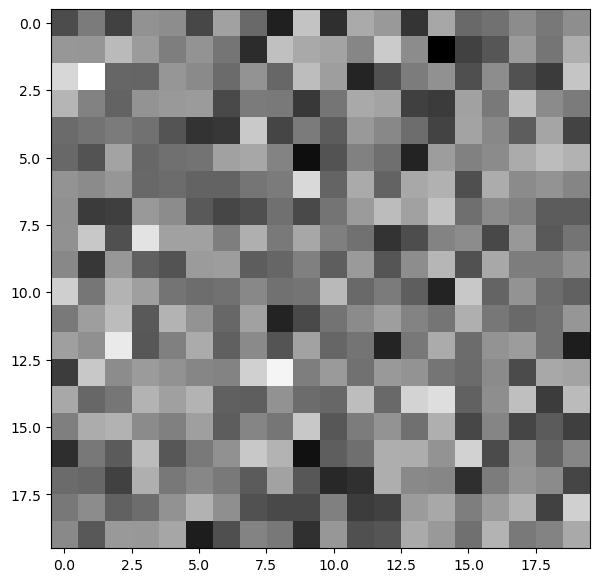

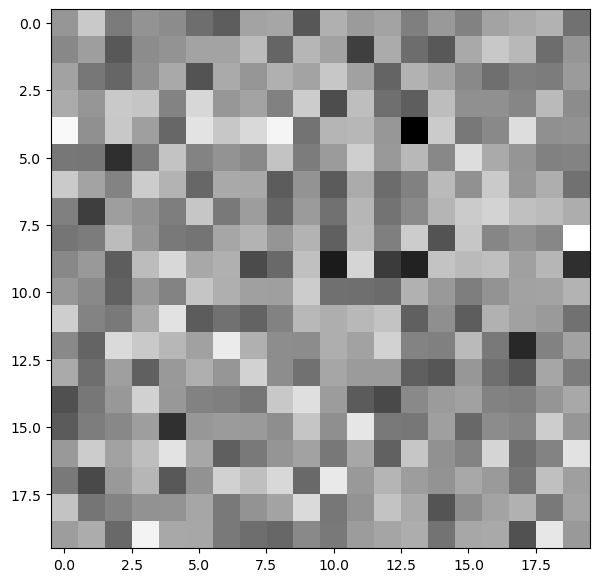

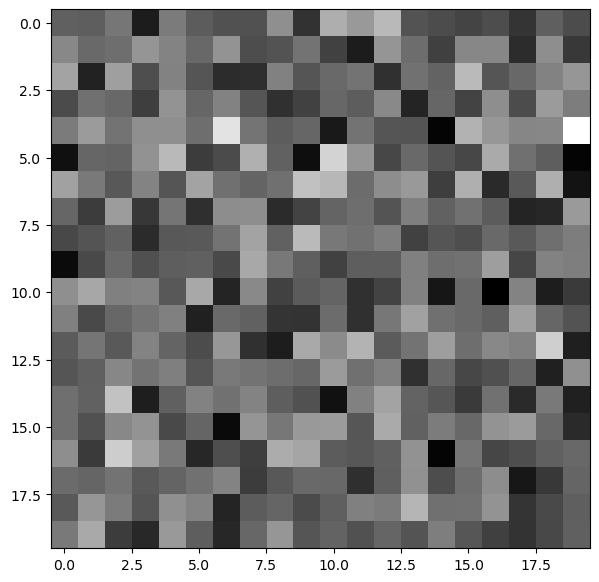

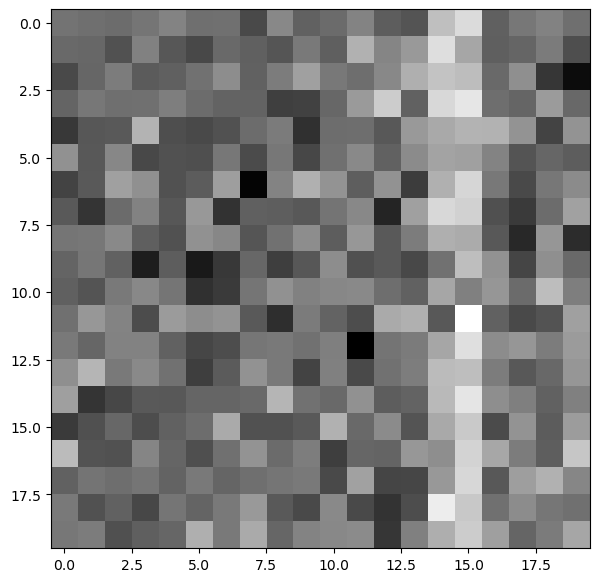

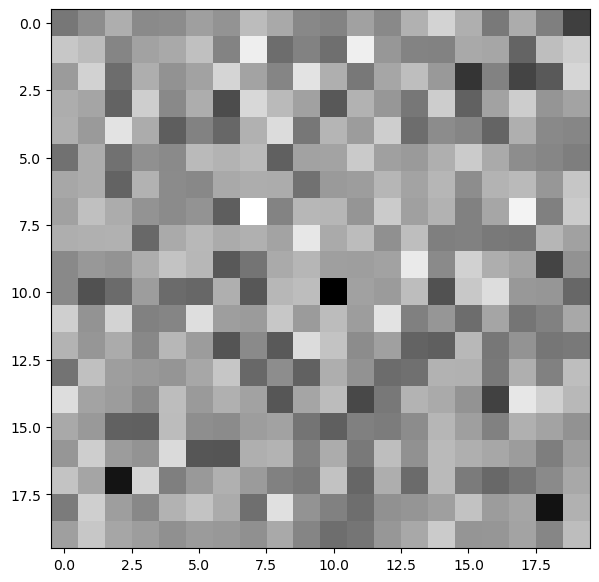

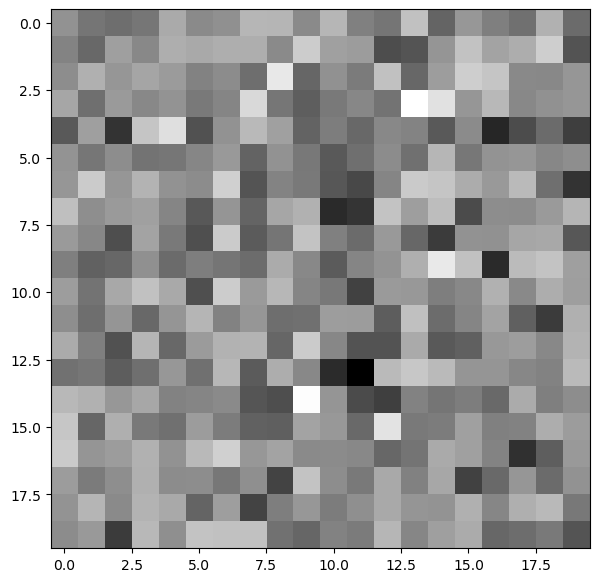

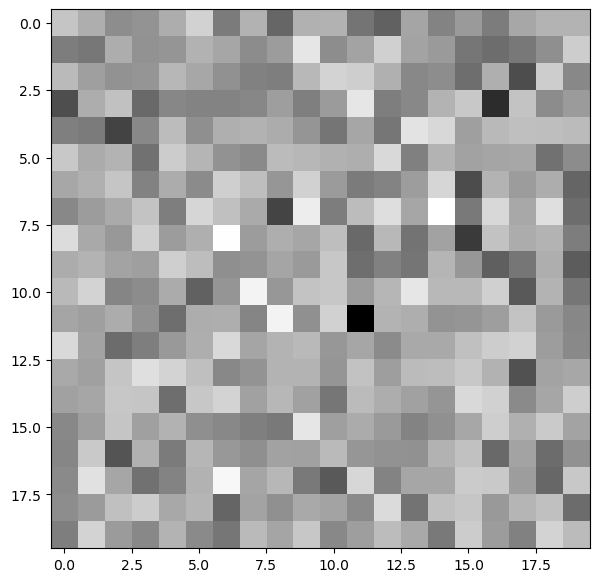

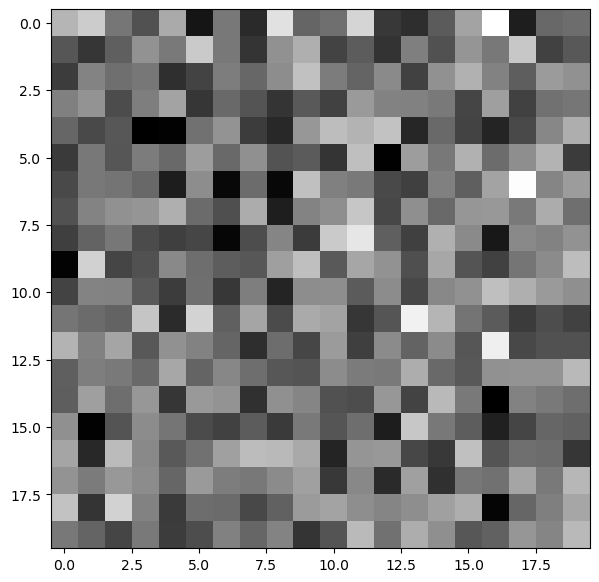

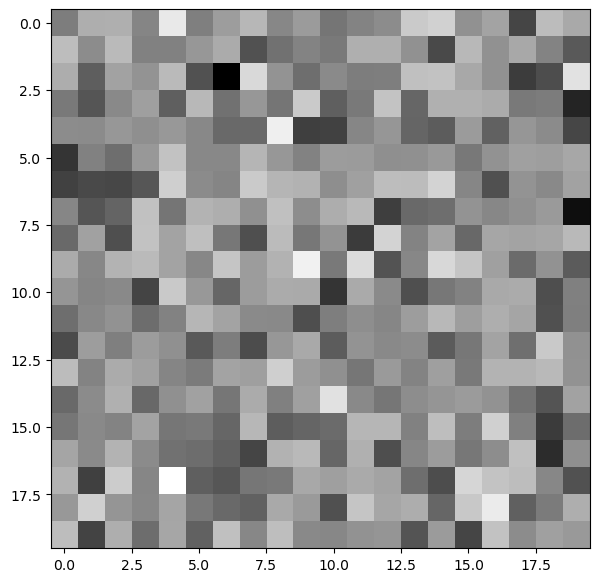

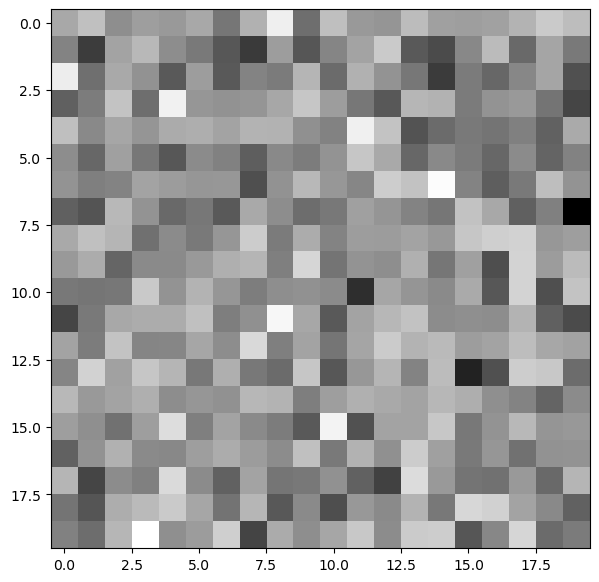

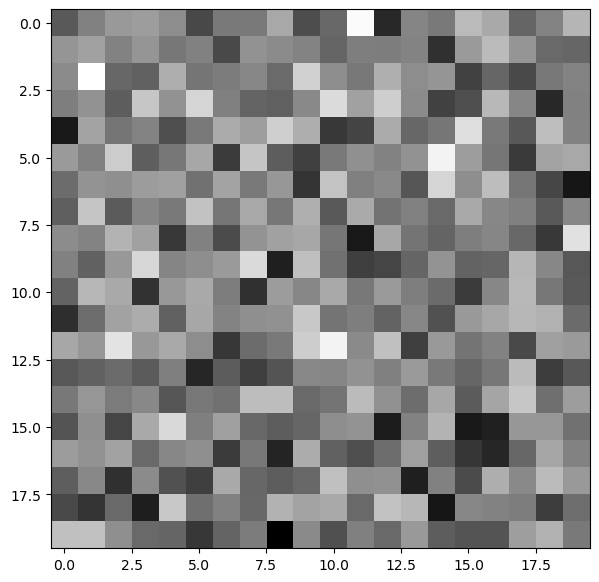

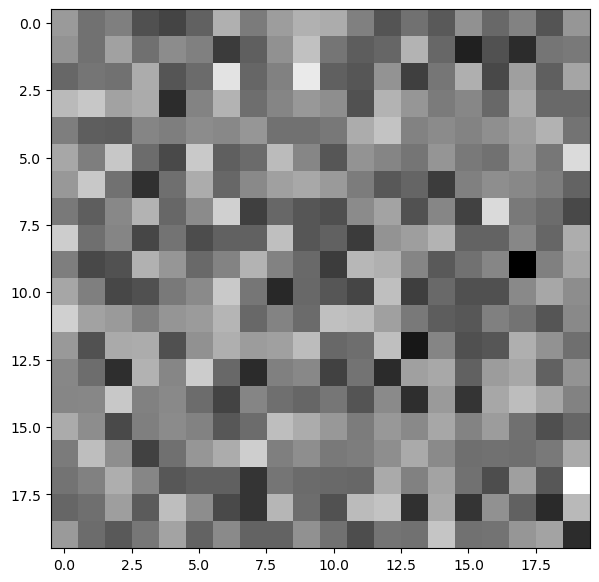

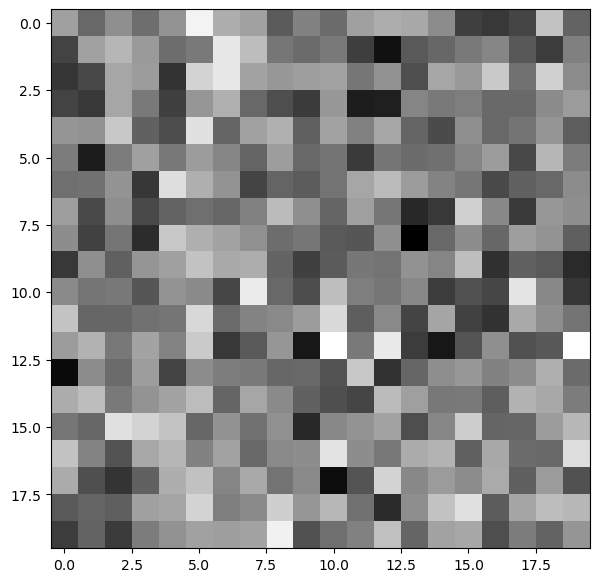

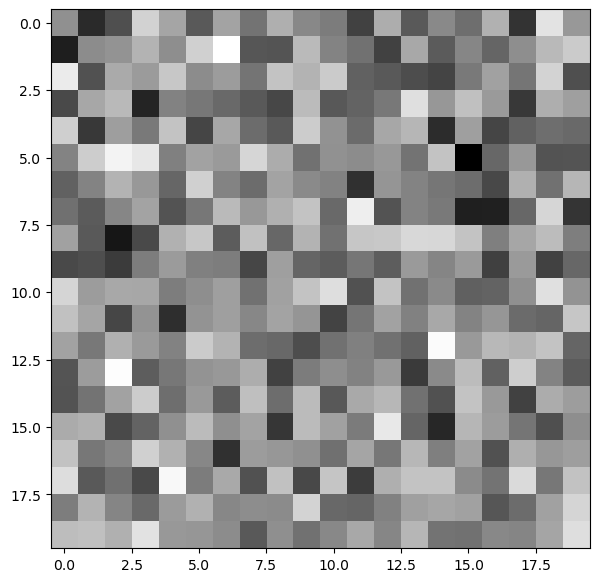

In [34]:
counter = 0
stamps_bg = get_10_background_stamps(norm, center_values_new_3, counter, plot=True)

In [37]:
np.shape(stamps_bg)

(25, 20, 20)

In [35]:
len(stamps_bg)

25

In [39]:
#HERES WHERE THE STUFF HAPPENS for the BACKGOUND postage stamps
path_to_save = "/lustre/lrspec/ZTF_data/2022_1014_copy/stamps_background/"
fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/implant_train/"

counter=0

for i, file in enumerate(os.listdir(fpath_image)):
    image_filename = os.fsdecode(file)
    filename_start = image_filename[:40]
    image_filename_full = fpath_image+image_filename
    print(image_filename)
    hdul=fits.open(image_filename_full)
    file1_array = hdul[1].data
    norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
    image = norm
    nrow, ncol = image.shape
    imagepath = path_to_save+"images/"+str(filename_start)+"_background_stamps"
    stamps_bg  = get_10_background_stamps(image,
                                            center_values_new_3, counter, plot=False)
    np.save(imagepath, stamps_bg)
    counter+=(len(stamps_bg)+1)

ztf_20221014279051_000501_zr_c04_x_0008.fits.fz
ztf_20221014279051_000501_zr_c15_x_0006.fits.fz
ztf_20221014169178_000802_zi_c12_x_0014.fits.fz
ztf_20221014162894_000802_zg_c07_x_0004.fits.fz
ztf_20221014279051_000501_zr_c09_x_0016.fits.fz
ztf_20221014169178_000802_zi_c10_x_0004.fits.fz
ztf_20221014162894_000802_zg_c05_x_0014.fits.fz
ztf_20221014279051_000501_zr_c06_x_0018.fits.fz
ztf_20221014169178_000802_zi_c14_x_0024.fits.fz
ztf_20221014279051_000501_zr_c11_x_0026.fits.fz
ztf_20221014162894_000802_zg_c03_x_0024.fits.fz
ztf_20221014279051_000501_zr_c06_x_0014.fits.fz
ztf_20221014162894_000802_zg_c14_x_0016.fits.fz
ztf_20221014169178_000802_zi_c01_x_0006.fits.fz
ztf_20221014162894_000802_zg_c05_x_0018.fits.fz
ztf_20221014169178_000802_zi_c10_x_0008.fits.fz
ztf_20221014162894_000802_zg_c07_x_0008.fits.fz
ztf_20221014169178_000802_zi_c12_x_0018.fits.fz
ztf_20221014162894_000802_zg_c08_x_0006.fits.fz
ztf_20221014279051_000501_zr_c04_x_0004.fits.fz
ztf_20221014162894_000802_zg_c16_x_0006.